# **Sharpening-Enhanced Image Classification Using a Custom Convolutional Neural Network and Pretrained Models with a Web Application for Real-Time Prediction**

Dataset Link: https://www.kaggle.com/datasets/samithsachidanandan/human-face-emotions/data

## Import Libraries

In [ ]:
# Import the required libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from PIL import Image,ImageEnhance
from collections import Counter

import cv2

from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.image import ImageDataGenerator
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.applications import MobileNetV3Small

import torch
import torchvision
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
import copy
from tqdm.auto import tqdm
import torch.optim as optim

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

## Dataset Setup

The dataset is available in the Kaggle input directory.

We will first define the dataset path and inspect its folder structure. The folder structure will help us identify the emotion classes and the number of images available in each class.

Keeping the dataset path in a single variable makes the notebook easier to maintain and prevents repeated hard-coded paths throughout the analysis.

In [ ]:
# Define the path to the Human Face Emotions dataset
dataset_path = "/kaggle/input/datasets/samithsachidanandan/human-face-emotions/Data"

# Display the dataset path to confirm that the correct location is being used
print("Dataset path:", dataset_path)

# Check whether the dataset path exists
print("Dataset path exists:", os.path.exists(dataset_path))

# Display the folders available inside the dataset directory
class_names = sorted([folder_name for folder_name in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, folder_name))])

print("\nEmotion classes:")
for class_name in class_names:
    print("-", class_name)

Dataset path: /kaggle/input/datasets/samithsachidanandan/human-face-emotions/Data
Dataset path exists: True

Emotion classes:
- Angry
- Fear
- Happy
- Sad
- Suprise


## Basic Statistics

The statistics include the total number of images, number of emotion classes, class distribution, image dimensions, image channels and pixel intensity values.

In [ ]:
# Dataset path
data_dir = "/kaggle/input/datasets/samithsachidanandan/human-face-emotions/Data"

# Store image paths and class names
image_paths = []
classes = []

# Read all class folders
for class_name in os.listdir(data_dir):
    class_path = os.path.join(data_dir, class_name)

    if os.path.isdir(class_path):
        for image_name in os.listdir(class_path):
            image_path = os.path.join(class_path, image_name)

            image_paths.append(image_path)
            classes.append(class_name)

# Create dataframe
df = pd.DataFrame({
    "filename": image_paths,
    "class": classes
})

print("Total images:", len(df))
print("\nClass distribution:")
print(df["class"].value_counts())

Total images: 59099

Class distribution:
class
Happy      18439
Sad        12553
Angry      10148
Fear        9732
Suprise     8227
Name: count, dtype: int64


In [ ]:
# Calculate the total number of images in the dataset
total_images = len(image_paths)

# Calculate the total number of emotion classes in the dataset
total_classes = len(class_names)

# Display the dataset dimensions
print("Dataset Dimensions")
print("-" * 30)
print("Total number of images:", total_images)
print("Total number of classes:", total_classes)

Dataset Dimensions
------------------------------
Total number of images: 59099
Total number of classes: 5


In [ ]:
# Create empty lists to store image paths and their corresponding class labels
class_labels = []

# Loop through every emotion class in the dataset
for class_name in class_names:

    # Create the complete path for the current emotion class
    class_path = os.path.join(dataset_path, class_name)

    # Loop through every file inside the current class folder
    for file_name in os.listdir(class_path):

        # Create the complete path for the current image
        image_path = os.path.join(class_path, file_name)

        # Check whether the current item is a file before adding it
        if os.path.isfile(image_path):

            # Store the image path
            image_paths.append(image_path)

            # Store the corresponding emotion class
            class_labels.append(class_name)

# Display the total number of image paths collected
print("Total images:", len(image_paths))

# Display the total number of class labels collected
print("Total labels:", len(class_labels))

Total images: 118198
Total labels: 59099


In [ ]:
# Count the number of images belonging to each emotion class
class_counts = Counter(class_labels)

# Create a DataFrame containing the class distribution
class_distribution = pd.DataFrame({
    "Class": class_names,
    "Image Count": [class_counts[class_name] for class_name in class_names]
})

# Calculate the percentage of images contributed by each class
class_distribution["Percentage"] = (class_distribution["Image Count"] / total_images) * 100

# Display the class distribution table
print("Class Distribution")
display(class_distribution)

Class Distribution


,Class,Image Count,Percentage
0,Angry,10148,17.171187
1,Fear,9732,16.467284
2,Happy,18439,31.200190
3,Sad,12553,21.240630
4,Suprise,8227,13.920709


In [ ]:
# Create empty lists to store image width, height and channel information
image_widths = []
image_heights = []
image_channels = []

# Loop through all image paths in the dataset
for image_path in image_paths:

    try:
        # Open the image without converting it into a NumPy array
        with Image.open(image_path) as image:

            # Store the image width
            image_widths.append(image.width)

            # Store the image height
            image_heights.append(image.height)

            # Store the number of image channels using the image mode
            if image.mode == "L":
                image_channels.append(1)
            elif image.mode == "RGB":
                image_channels.append(3)
            elif image.mode == "RGBA":
                image_channels.append(4)
            else:
                image_channels.append(len(image.getbands()))

    except Exception as error:
        # Display information about images that could not be processed
        print("Unable to process:", image_path)
        print("Error:", error)

# Create a DataFrame containing the image properties
image_properties = pd.DataFrame({
    "Width": image_widths,
    "Height": image_heights,
    "Channels": image_channels
})

# Display descriptive statistics for width and height
display(image_properties[["Width", "Height"]].describe())

# Count the number of images for each channel configuration
channel_counts = Counter(image_channels)

# Display the channel distribution
print("\nChannel Distribution")
print("-" * 30)

for channel, count in sorted(channel_counts.items()):
    print(f"{channel} channel(s): {count} images")

,Width,Height
count,118198.000000,118198.000000
mean,80.886056,80.393611
std,336.622246,335.069974
min,48.000000,48.000000
25%,48.000000,48.000000
50%,48.000000,48.000000
75%,48.000000,48.000000
max,8957.000000,8660.000000



Channel Distribution
------------------------------
1 channel(s): 115516 images
3 channel(s): 2676 images
4 channel(s): 6 images


In [ ]:
# Initialize variables for calculating pixel intensity statistics incrementally
pixel_min = np.inf
pixel_max = -np.inf
pixel_sum = 0.0
pixel_sum_squared = 0.0
pixel_count = 0

# Loop through every image in the dataset
for image_path in image_paths:

    try:
        # Open the current image
        with Image.open(image_path) as image:

            # Convert the image into a NumPy array for pixel analysis
            image_array = np.asarray(image, dtype=np.float64)

            # Flatten the image array so all pixel values can be processed together
            image_array = image_array.ravel()

            # Update the minimum pixel intensity
            pixel_min = min(pixel_min, np.min(image_array))

            # Update the maximum pixel intensity
            pixel_max = max(pixel_max, np.max(image_array))

            # Add the pixel values to the running total
            pixel_sum += np.sum(image_array)

            # Add the squared pixel values to the running squared total
            pixel_sum_squared += np.sum(image_array ** 2)

            # Update the total number of pixels processed
            pixel_count += image_array.size

    except Exception as error:
        # Display information about images that could not be processed
        print("Unable to process:", image_path)
        print("Error:", error)

# Calculate the mean pixel intensity
pixel_mean = pixel_sum / pixel_count

# Calculate the variance using the accumulated values
pixel_variance = (pixel_sum_squared / pixel_count) - (pixel_mean ** 2)

# Prevent a very small negative value caused by floating-point precision
pixel_variance = max(pixel_variance, 0)

# Calculate the standard deviation
pixel_std = np.sqrt(pixel_variance)

# Display the pixel intensity statistics
print("Pixel Intensity Statistics")
print("-" * 30)
print("Minimum:", pixel_min)
print("Maximum:", pixel_max)
print("Mean:", pixel_mean)
print("Standard Deviation:", pixel_std)

Pixel Intensity Statistics
------------------------------
Minimum: 0.0
Maximum: 255.0
Mean: 104.7117988945436
Standard Deviation: 74.32165500847299


In [ ]:
# Create the results directory to store the calculated statistics.
os.makedirs("/kaggle/working/results", exist_ok=True)

# Save the class distribution results.
class_distribution.to_csv("/kaggle/working/results/class_distribution.csv", index=False)

# Save the image width, height and channel information.
image_properties.to_csv("/kaggle/working/results/image_properties.csv", index=False)

# Create a DataFrame containing the overall pixel intensity statistics.
pixel_statistics = pd.DataFrame({
    "Statistic": ["Minimum", "Maximum", "Mean", "Standard Deviation"],
    "Value": [pixel_min, pixel_max, pixel_mean, pixel_std]
})

# Save the pixel intensity statistics.
pixel_statistics.to_csv("/kaggle/working/results/pixel_statistics.csv", index=False)

# Display a confirmation message.
print("Basic Statistics results saved successfully.")

# Display the saved pixel statistics.
display(pixel_statistics)

Basic Statistics results saved successfully.


,Statistic,Value
0,Minimum,0.000000
1,Maximum,255.000000
2,Mean,104.711799
3,Standard Deviation,74.321655


***Basic Statistics Summary***

- The dataset contains **59,099 images** across **5 emotion classes**: Angry, Fear, Happy, Sad and Suprise.
- The class distribution is imbalanced. **Happy** is the largest class with **18,439 images (31.20%)**, while **Suprise** is the smallest with **8,227 images (13.92%)**.
- Most images have a resolution of **48 × 48 pixels**, and the dataset is predominantly grayscale, with **57,758 images having 1 channel**.
- A small number of images have unusually large dimensions, with maximum width of **8,957 pixels** and maximum height of **8,660 pixels**.
- Pixel intensities range from **0 to 255**, with a mean of **104.71** and a standard deviation of **74.32**, indicating considerable variation in image brightness and contrast.
- The calculated statistics have been saved in the `results` directory so that they can be reused without repeating the full dataset scan.

In [ ]:
# Load the saved Basic Statistics files so they can be reused without scanning the full dataset again.
class_distribution = pd.read_csv("/kaggle/working/results/class_distribution.csv")
image_properties = pd.read_csv("/kaggle/working/results/image_properties.csv")
pixel_statistics = pd.read_csv("/kaggle/working/results/pixel_statistics.csv")

# Recreate the variables used by the EDA plots.
image_widths = image_properties["Width"].tolist()
image_heights = image_properties["Height"].tolist()
image_channels = image_properties["Channels"].tolist()

In [ ]:
# Display the saved image Class Distribution.
print("Class Distribution:")
display(class_distribution)


Class Distribution:


,Class,Image Count,Percentage
0,Angry,10148,17.171187
1,Fear,9732,16.467284
2,Happy,18439,31.200190
3,Sad,12553,21.240630
4,Suprise,8227,13.920709


In [ ]:
# Display the saved image property statistics.
print("Image Properties:")
display(image_properties.head())


Image Properties:


,Width,Height,Channels
0,48,48,1
1,48,48,1
2,48,48,1
3,48,48,1
4,48,48,1


In [ ]:
# Display the saved pixel intensity statistics.
print("Pixel Statistics:")
display(pixel_statistics)


Pixel Statistics:


,Statistic,Value
0,Minimum,0.000000
1,Maximum,255.000000
2,Mean,104.711799
3,Standard Deviation,74.321655


## Exploratory Data Analysis

In [ ]:
# Define the common color palette that will be used consistently across all EDA plots
plot_colors = ["#5ec2a6", "#339b80", "#00755d", "#00513b", "#002f1c"]

# Define the common figure size for all EDA plots
figure_size = (10, 6)

# Define common font sizes according to the project requirements
title_font_size = 18
axis_font_size = 16
annotation_font_size = 14

# Define the common text color for titles, labels and annotations
text_color = "gray"

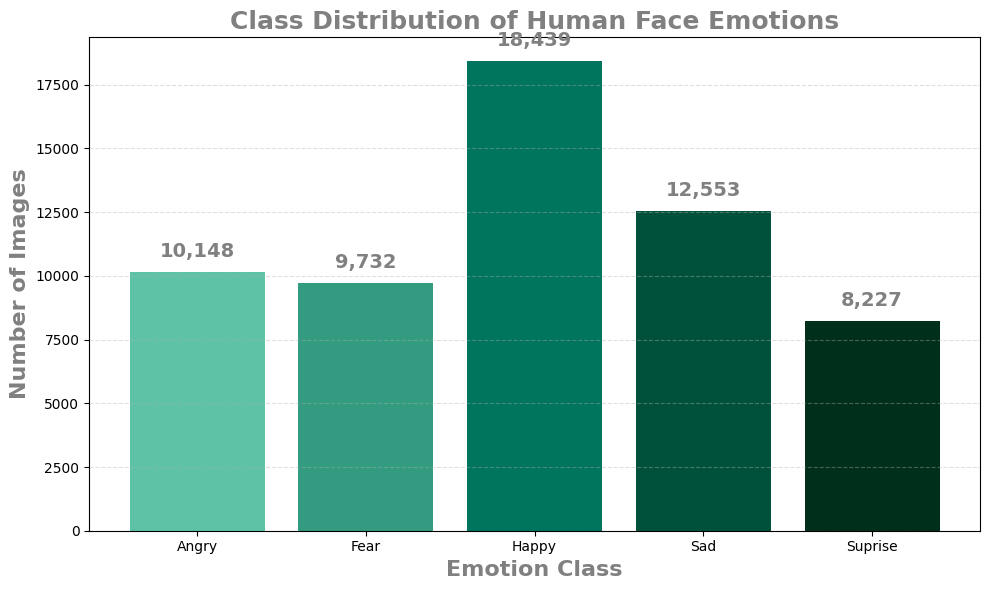

In [ ]:
# Create the class distribution DataFrame using the verified statistics.
class_distribution = pd.DataFrame({
    "Class": ["Angry", "Fear", "Happy", "Sad", "Suprise"],
    "Images": [10148, 9732, 18439, 12553, 8227],
    "Percentage": [17.17, 16.47, 31.20, 21.24, 13.92]
})

# Create the figure using the required figure size.
plt.figure(figsize=figure_size)

# Create the bar plot using the common plot palette.
bars = plt.bar(class_distribution["Class"], class_distribution["Images"], color=plot_colors)

# Set the x-axis positions and labels so that the class names remain centered below the bars.
plt.xticks(range(len(class_distribution)), class_distribution["Class"], rotation=0)

# Add image count annotations above each bar.
for bar in bars:
    image_count = int(bar.get_height())
    plt.annotate(f"{image_count:,}", xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()), xytext=(0, 8), textcoords="offset points", ha="center", va="bottom", fontsize=annotation_font_size, fontweight="bold", color=text_color)

# Add the plot title.
plt.title("Class Distribution of Human Face Emotions", fontsize=title_font_size, fontweight="bold", color=text_color)

# Add the x-axis label.
plt.xlabel("Emotion Class", fontsize=axis_font_size, fontweight="bold", color=text_color)

# Add the y-axis label.
plt.ylabel("Number of Images", fontsize=axis_font_size, fontweight="bold", color=text_color)

# Apply the required grid background.
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Adjust the layout.
plt.tight_layout()

# Display the plot.
plt.show()

The class distribution shows that **Happy** has the highest number of images with **18,439 images**, while **Suprise** has the lowest with **8,227 images**. The classes are therefore **not perfectly balanced**, with a noticeable difference in the number of images between the largest and smallest classes. This class imbalance should be considered during model development and evaluation because a model may learn more effectively from classes with a larger number of training examples.

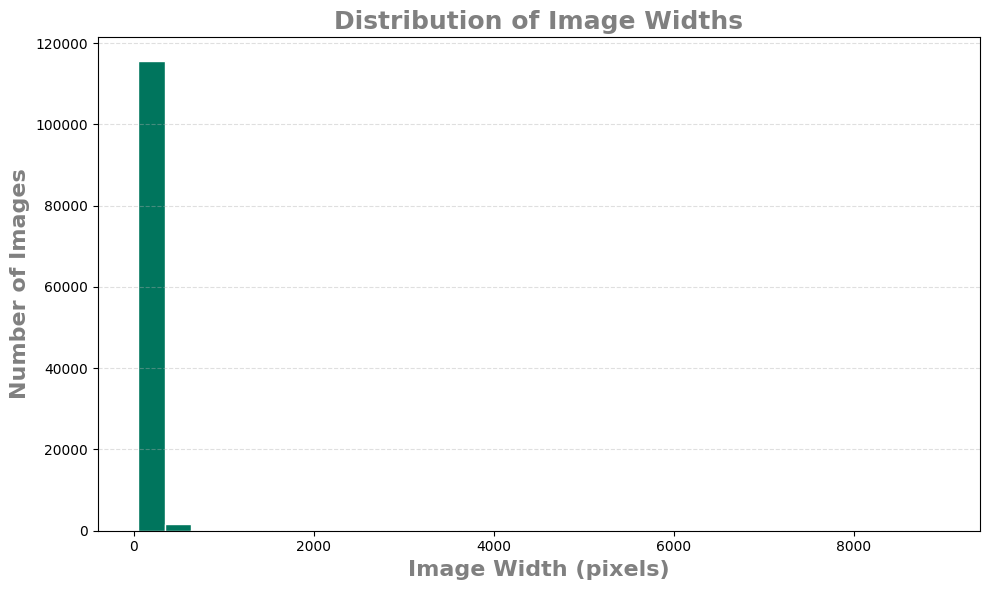

In [ ]:
# Create the figure using the required figure size.
plt.figure(figsize=figure_size)

# Create the image width histogram using the common plot palette.
plt.hist(image_properties["Width"], bins=30, color=plot_colors[2], edgecolor="white")

# Add the plot title.
plt.title("Distribution of Image Widths", fontsize=title_font_size, fontweight="bold", color=text_color)

# Add the x-axis label.
plt.xlabel("Image Width (pixels)", fontsize=axis_font_size, fontweight="bold", color=text_color)

# Add the y-axis label.
plt.ylabel("Number of Images", fontsize=axis_font_size, fontweight="bold", color=text_color)

# Apply the required grid background.
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Adjust the layout.
plt.tight_layout()

# Display the plot.
plt.show()

The image widths are heavily concentrated around a common small width, showing that most images have a consistent width. A small portion of the dataset contains images with much larger widths, creating a long right-skewed distribution. These unusually large image widths indicate that the dataset contains some images with dimensions that differ significantly from the majority of the images.

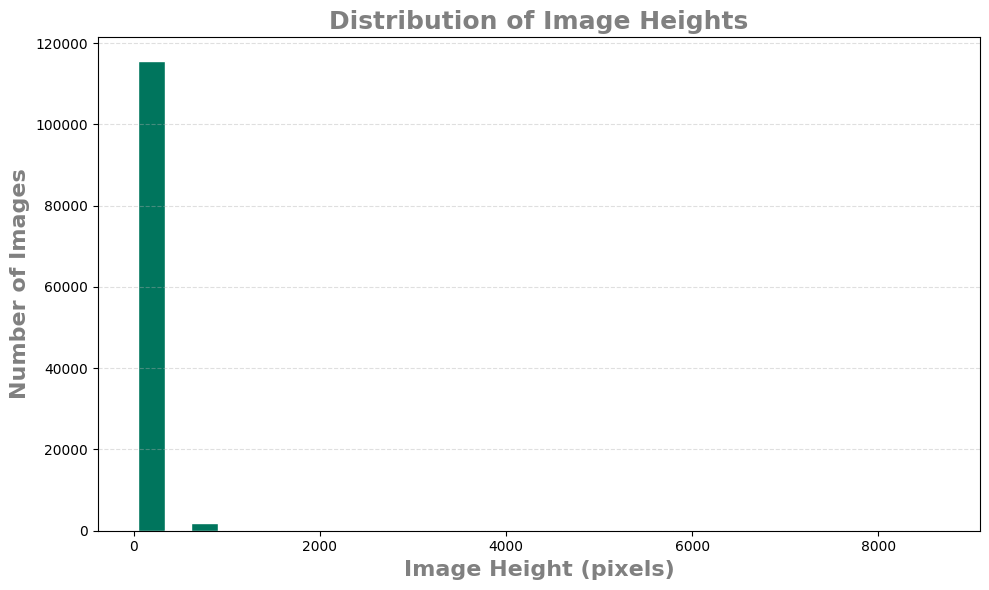

In [ ]:
# Create the figure using the required figure size.
plt.figure(figsize=figure_size)

# Create the image height histogram using the common plot palette.
plt.hist(image_properties["Height"], bins=30, color=plot_colors[2], edgecolor="white")

# Add the plot title.
plt.title("Distribution of Image Heights", fontsize=title_font_size, fontweight="bold", color=text_color)

# Add the x-axis label.
plt.xlabel("Image Height (pixels)", fontsize=axis_font_size, fontweight="bold", color=text_color)

# Add the y-axis label.
plt.ylabel("Number of Images", fontsize=axis_font_size, fontweight="bold", color=text_color)

# Apply the required grid background.
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Adjust the layout.
plt.tight_layout()

# Display the plot.
plt.show()

The image heights are heavily concentrated around a common small height, showing that most images have a consistent height. A small portion of the dataset contains images with much larger heights, creating a long right-skewed distribution. These unusually large image heights indicate that the dataset contains some images with dimensions that differ significantly from the majority of the images.

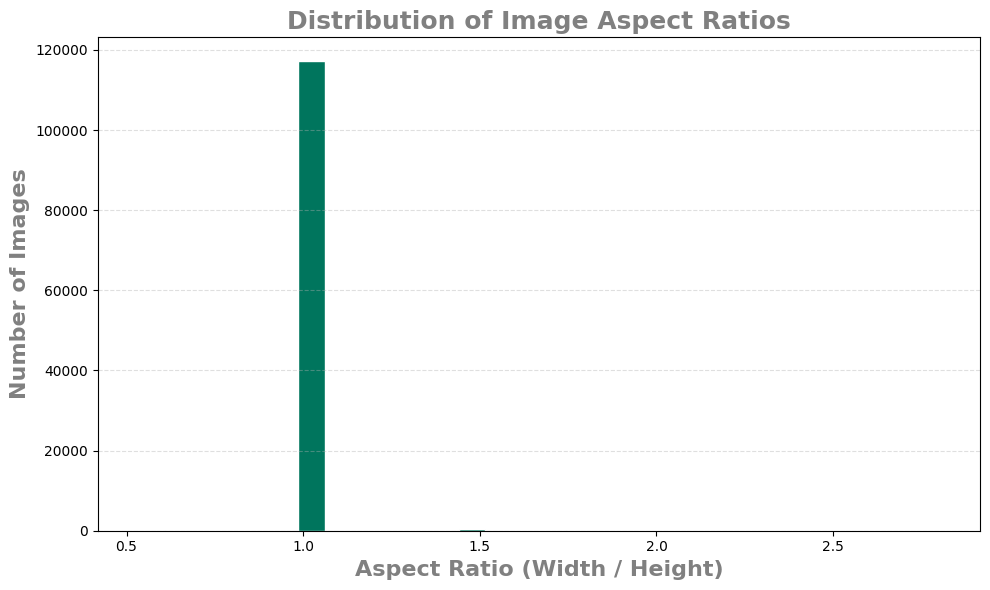

In [ ]:
# Calculate the aspect ratio of each image.
image_properties["Aspect_Ratio"] = image_properties["Width"] / image_properties["Height"]

# Create the figure using the required figure size.
plt.figure(figsize=figure_size)

# Create the aspect ratio histogram using the common plot palette.
plt.hist(image_properties["Aspect_Ratio"], bins=30, color=plot_colors[2], edgecolor="white")

# Add the plot title.
plt.title("Distribution of Image Aspect Ratios", fontsize=title_font_size, fontweight="bold", color=text_color)

# Add the x-axis label.
plt.xlabel("Aspect Ratio (Width / Height)", fontsize=axis_font_size, fontweight="bold", color=text_color)

# Add the y-axis label.
plt.ylabel("Number of Images", fontsize=axis_font_size, fontweight="bold", color=text_color)

# Apply the required grid background.
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Adjust the layout.
plt.tight_layout()

# Display the plot.
plt.show()

The aspect ratio distribution is strongly concentrated around a square shape, indicating that most images have similar width and height. Only a small portion of the images have noticeably different proportions, producing a wider spread in the distribution. Overall, the dataset is predominantly composed of approximately square images, which is suitable for standard image classification preprocessing.

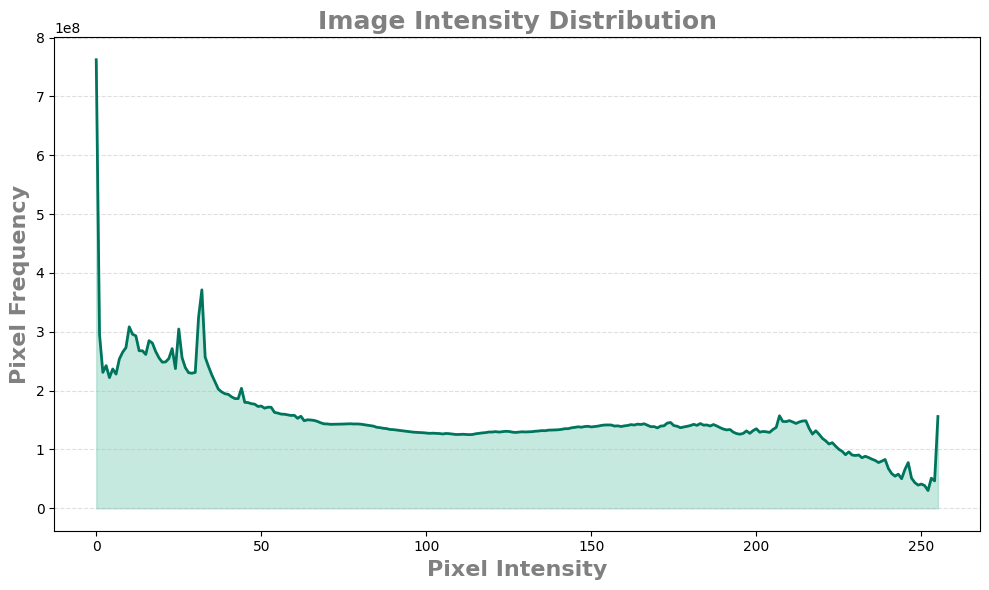

In [ ]:
# Initialize an array to store the frequency of each pixel intensity value.
pixel_intensity_counts = np.zeros(256, dtype=np.int64)

# Process each image and count its pixel intensity values.
for image_path in image_paths:
    try:
        with Image.open(image_path) as image:
            image_array = np.asarray(image, dtype=np.uint8)
            pixel_intensity_counts += np.bincount(image_array.ravel(), minlength=256)
    except Exception as error:
        print("Unable to process:", image_path)
        print("Error:", error)

# Create the figure using the required figure size.
plt.figure(figsize=figure_size)

# Plot the pixel intensity distribution using the common plot palette.
plt.plot(range(256), pixel_intensity_counts, color=plot_colors[2], linewidth=2)

# Fill the area below the intensity distribution.
plt.fill_between(range(256), pixel_intensity_counts, color=plot_colors[0], alpha=0.35)

# Add the plot title.
plt.title("Image Intensity Distribution", fontsize=title_font_size, fontweight="bold", color=text_color)

# Add the x-axis label.
plt.xlabel("Pixel Intensity", fontsize=axis_font_size, fontweight="bold", color=text_color)

# Add the y-axis label.
plt.ylabel("Pixel Frequency", fontsize=axis_font_size, fontweight="bold", color=text_color)

# Apply the required grid background.
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Adjust the layout.
plt.tight_layout()

# Display the plot.
plt.show()

The pixel intensity distribution shows that the dataset contains a wide range of pixel brightness values. The distribution is more concentrated toward the lower intensity levels, indicating that darker pixel values are more common in the images.The frequency gradually changes across the intensity range, showing considerable variation in brightness and contrast among the images.

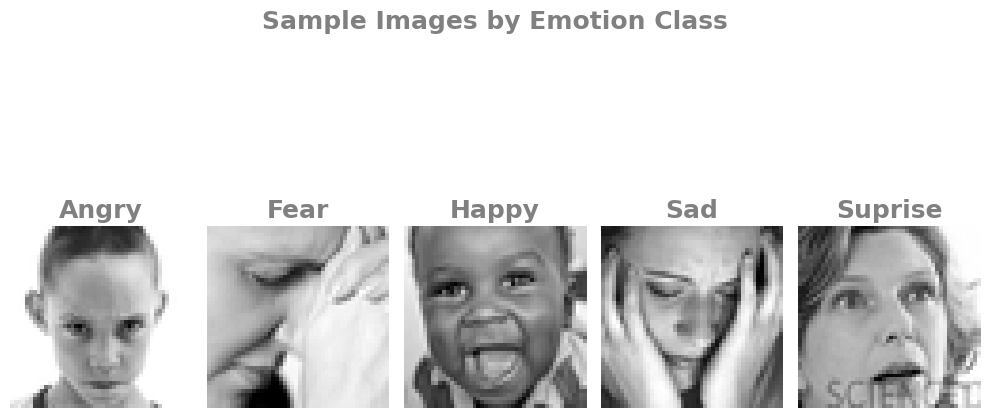

In [ ]:
# Create the figure with one image for each emotion class.
fig, axes = plt.subplots(1, len(class_names), figsize=(10, 6))

# Display one sample image from each class.
for index, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_path, class_name)
    sample_file = next(file_name for file_name in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, file_name)))
    sample_path = os.path.join(class_path, sample_file)

    # Open and display the sample image.
    with Image.open(sample_path) as image:
        axes[index].imshow(image, cmap="gray")

    # Add the class name below each image.
    axes[index].set_title(class_name, fontsize=title_font_size, fontweight="bold", color=text_color)
    axes[index].axis("off")

# Add an overall title.
fig.suptitle("Sample Images by Emotion Class", fontsize=title_font_size, fontweight="bold", color=text_color)

# Adjust the layout.
plt.tight_layout()
plt.show()

The sample images show visible differences in facial expressions across the emotion classes. There is also noticeable variation in facial appearance, pose and image quality among the samples. Some emotion classes have visually similar facial characteristics, which indicates that distinguishing between certain emotions may be challenging for the classification model.

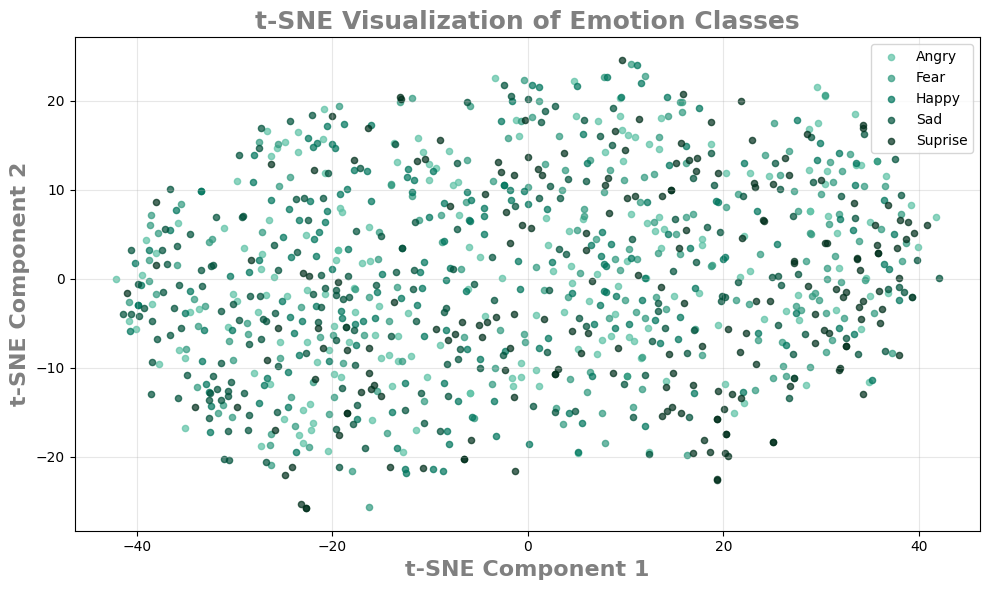

In [ ]:
# Select a fixed number of images from each class so that the t-SNE calculation remains manageable.
tsne_sample_count = 200
rng = np.random.default_rng(42)
tsne_paths = []
tsne_labels = []

# Collect an equal number of samples from each emotion class.
for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    class_files = [file_name for file_name in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, file_name))]
    selected_files = rng.choice(class_files, size=min(tsne_sample_count, len(class_files)), replace=False)

    for file_name in selected_files:
        tsne_paths.append(os.path.join(class_path, file_name))
        tsne_labels.append(class_name)

# Convert the sampled images into compact grayscale feature vectors.
tsne_features = []
valid_tsne_labels = []

for image_path, label in zip(tsne_paths, tsne_labels):
    try:
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        image = cv2.resize(image, (32, 32), interpolation=cv2.INTER_AREA)
        tsne_features.append(image.ravel() / 255.0)
        valid_tsne_labels.append(label)
    except Exception:
        continue

# Reduce the feature dimension before applying t-SNE to improve computational efficiency.
pca = PCA(n_components=50, random_state=42)
pca_features = pca.fit_transform(np.array(tsne_features))

# Project the sampled image features into two dimensions using t-SNE.
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init="pca", learning_rate="auto")
tsne_features_2d = tsne.fit_transform(pca_features)

# Create the t-SNE scatter plot.
plt.figure(figsize=figure_size)

for class_name, color in zip(class_names, plot_colors):
    class_mask = np.array(valid_tsne_labels) == class_name
    plt.scatter(tsne_features_2d[class_mask, 0], tsne_features_2d[class_mask, 1], label=class_name, color=color, alpha=0.7, s=20)

# Add the plot title, axis labels and legend.
plt.title("t-SNE Visualization of Emotion Classes", fontsize=title_font_size, fontweight="bold", color=text_color)
plt.xlabel("t-SNE Component 1", fontsize=axis_font_size, fontweight="bold", color=text_color)
plt.ylabel("t-SNE Component 2", fontsize=axis_font_size, fontweight="bold", color=text_color)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The t-SNE plot provides a two-dimensional view of the sampled image features and shows how the different emotion classes are distributed in feature space. Overlapping regions indicate that some facial emotion classes have visually similar feature representations, while more separated regions indicate greater differences in the sampled image features.

## Data Preprocessing

The preprocessing pipeline is designed to improve image quality while preserving important facial features related to emotion classification. The pipeline includes gamma correction, image denoising, resizing, RGB conversion and normalization. Data augmentation will be applied only to the training images.

In [ ]:
# Sharpen the image
class SharpenImage:
    def __init__(self, factor=2.0):
        self.factor = factor

    def __call__(self, image):
        enhancer = ImageEnhance.Sharpness(image)
        return enhancer.enhance(self.factor)

Image sharpening is a technique used to make an image appear clearer and more detailed. It enhances the edges and fine details, making objects look more defined and distinct.
Sharpening should be applied carefully, as too much can create unwanted noise and unnatural edges.

In [ ]:
# Apply the selected preprocessing steps
def preprocess_image(image):
    # Resize to 224 × 224
    image = image.resize((224, 224))

    # Convert RGB to grayscale
    image = image.convert("L")

    # Convert grayscale to 3 channels
    image = np.stack([np.array(image)] * 3, axis=-1)
    image = Image.fromarray(image.astype(np.uint8))

    # Sharpen with factor 2.0
    image = SharpenImage(factor=2.0)(image)

    # Convert to NumPy array
    image = np.asarray(image).astype(np.float32)

    # Scale pixel values to 0-1
    image = image / 255.0

    # ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    image = (image - mean) / std

    return image

In [ ]:
# Select one sample image
sample_path = "/kaggle/input/datasets/samithsachidanandan/human-face-emotions/Data/Angry/" + os.listdir("/kaggle/input/datasets/samithsachidanandan/human-face-emotions/Data/Angry")[0]

# Load the image
sample_image = Image.open(sample_path).convert("RGB")

# Apply preprocessing
processed_image = preprocess_image(sample_image)

# Print the results
print("Original image size:", sample_image.size)
print("Processed image shape:", processed_image.shape)
print("Processed image minimum:", processed_image.min())
print("Processed image maximum:", processed_image.max())

Original image size: (48, 48)
Processed image shape: (224, 224, 3)
Processed image minimum: -2.0665298
Processed image maximum: 2.64


## Dataset Splitting

The dataset is divided into three subsets:

- **Training Set:** 70% of the images, used to train the model.
- **Validation Set:** 15% of the images, used to monitor model performance during training and tune the model.
- **Testing Set:** 15% of the images, used to evaluate the final model on unseen data.

A **stratified split** is used to maintain a similar proportion of each emotion class in the training, validation, and testing sets.

A fixed random state is used to make the dataset split reproducible.

In [ ]:
# First split: 70% training and 30% temporary data
train_df, temp_df = train_test_split(df,test_size=0.30,stratify=df["class"],random_state=42)

# Second split: divide the 30% temporary data equally
validation_df, test_df = train_test_split(temp_df,test_size=0.50,stratify=temp_df["class"],random_state=42)

print("Training samples:", len(train_df))
print("Validation samples:", len(validation_df))
print("Testing samples:", len(test_df))

Training samples: 41369
Validation samples: 8865
Testing samples: 8865


In [ ]:
# Map emotion class names to integer labels.
class_to_idx = {"Angry": 0,"Fear": 1,"Happy": 2,"Sad": 3,"Suprise": 4}

# PyTorch Dataset for the emotion images.
class EmotionDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        # Get image path and class name.
        image_path = self.dataframe.iloc[index]["filename"]
        class_name = self.dataframe.iloc[index]["class"]

        # Load the image as RGB.
        image = Image.open(image_path).convert("RGB")

        # Resize to 224 × 224.
        image = image.resize((224, 224))

        # Convert RGB to grayscale.
        image = image.convert("L")

        # Convert grayscale to 3 channels.
        image = np.stack([np.array(image)] * 3, axis=-1)

        # Convert NumPy array back to PIL image.
        image = Image.fromarray(image.astype(np.uint8))

        # Sharpen with factor 2.0.
        enhancer = ImageEnhance.Sharpness(image)
        image = enhancer.enhance(2.0)

        # Convert image to NumPy float32.
        image = np.asarray(image).astype(np.float32)

        # Scale pixel values to 0-1.
        image = image / 255.0

        # Apply ImageNet normalization.
        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
        image = (image - mean) / std

        # Convert HWC → CHW for PyTorch.
        image = np.transpose(image, (2, 0, 1))

        # Convert image to PyTorch tensor.
        image = torch.tensor(image, dtype=torch.float32)

        # Convert class name to integer label.
        label = class_to_idx[class_name]

        return image, torch.tensor(label, dtype=torch.long)

In [ ]:
# Create PyTorch datasets using the existing data split.
train_dataset = EmotionDataset(train_df)
validation_dataset = EmotionDataset(validation_df)
test_dataset = EmotionDataset(test_df)

print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Testing images:", len(test_dataset))

Training images: 41369
Validation images: 8865
Testing images: 8865


In [ ]:
# Batch size required for model training.
batch_size = 64

# Create DataLoaders.
train_loader = DataLoader(train_dataset,batch_size=batch_size,shuffle=True,num_workers=0,pin_memory=True)

validation_loader = DataLoader(validation_dataset,batch_size=batch_size,shuffle=False,num_workers=0,pin_memory=True)

test_loader = DataLoader(test_dataset,batch_size=batch_size,shuffle=False,num_workers=0,pin_memory=True)
print("DataLoaders created successfully.")

DataLoaders created successfully.


In [ ]:
# Load one batch to verify the PyTorch pipeline.
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image data type:", images.dtype)
print("Labels:", labels[:10])
print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

Images shape: torch.Size([64, 3, 224, 224])
Labels shape: torch.Size([64])
Image data type: torch.float32
Labels: tensor([1, 3, 3, 3, 1, 4, 3, 4, 2, 3])
Minimum pixel value: -2.1179039478302
Maximum pixel value: 2.640000104904175


##  Deep Learning Models

### Supportive Functions

In [ ]:
# Reusable function for calculating all evaluation metrics.
def calculate_metrics(model, data_loader, device, class_names):

    # Set the model to evaluation mode.
    model.eval()

    # Store true labels, predicted labels and probabilities.
    true_labels = []
    predicted_labels = []
    predicted_probabilities = []

    # Disable gradient calculation during evaluation.
    with torch.no_grad():

        for images, labels in data_loader:

            # Move images and labels to the selected device.
            images = images.to(device)
            labels = labels.to(device)

            # Generate model outputs.
            outputs = model(images)

            # Convert outputs to probabilities.
            probabilities = torch.softmax(outputs, dim=1)

            # Get predicted class.
            predictions = torch.argmax(probabilities, dim=1)

            # Store results.
            true_labels.extend(labels.cpu().numpy())
            predicted_labels.extend(predictions.cpu().numpy())
            predicted_probabilities.extend(probabilities.cpu().numpy())

    # Convert results to NumPy arrays.
    true_labels = np.array(true_labels)
    predicted_labels = np.array(predicted_labels)
    predicted_probabilities = np.array(predicted_probabilities)

    # Calculate Accuracy.
    accuracy = accuracy_score(true_labels,predicted_labels)

    # Calculate weighted Precision.
    precision = precision_score(true_labels,predicted_labels,average="weighted",zero_division=0)

    # Calculate weighted Recall.
    recall = recall_score(true_labels,predicted_labels,average="weighted",zero_division=0)

    # Calculate weighted F1-Score.
    f1 = f1_score(true_labels,predicted_labels,average="weighted",zero_division=0)

    # Create one-hot encoded true labels.
    one_hot_labels = np.eye(len(class_names))[true_labels]

    # Calculate multiclass Brier Score.
    brier_score = np.mean(np.sum((predicted_probabilities - one_hot_labels) ** 2,axis=1) )

    # Store all metrics.
    metrics = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Brier Score": brier_score
    }

    return metrics, true_labels, predicted_labels, predicted_probabilities

In [ ]:
def plot_learning_curve(model_name, train_losses, validation_losses, train_accuracies, validation_accuracies):
    # Create the epoch values for the learning curves.
    epochs = range(1, len(train_losses) + 1)

    # Create a figure with two plots arranged in one row.
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot the training loss using a light colour.
    axes[0].plot(epochs, train_losses, color=plot_colors[1], linewidth=2, label="Training Loss")

    # Plot the validation loss using a dark colour.
    axes[0].plot(epochs, validation_losses, color=plot_colors[0], linewidth=2, label="Validation Loss")

    # Set the title of the loss plot.
    axes[0].set_title(f"{model_name} Loss Curve", fontsize=title_font_size)

    # Set the label for the loss plot x-axis.
    axes[0].set_xlabel("Epochs", fontsize=axis_font_size)

    # Set the label for the loss plot y-axis.
    axes[0].set_ylabel("Loss", fontsize=axis_font_size)

    # Display the legend for the loss curves.
    axes[0].legend()

    # Add a grid to make the loss values easier to read.
    axes[0].grid(alpha=0.3)

    # Plot the training accuracy using a light colour.
    axes[1].plot(epochs, train_accuracies, color=plot_colors[1], linewidth=2, label="Training Accuracy")

    # Plot the validation accuracy using a dark colour.
    axes[1].plot(epochs, validation_accuracies, color=plot_colors[0], linewidth=2, label="Validation Accuracy")

    # Set the title of the accuracy plot.
    axes[1].set_title(f"{model_name} Accuracy Curve", fontsize=title_font_size)

    # Set the label for the accuracy plot x-axis.
    axes[1].set_xlabel("Epochs", fontsize=axis_font_size)

    # Set the label for the accuracy plot y-axis.
    axes[1].set_ylabel("Accuracy", fontsize=axis_font_size)

    # Set the accuracy range for easier comparison.
    axes[1].set_ylim(0, 1.0)

    # Display the legend for the accuracy curves.
    axes[1].legend()

    # Add a grid to make the accuracy values easier to read.
    axes[1].grid(alpha=0.3)

    # Set the overall title for the learning curves.
    fig.suptitle(f"{model_name} Learning Curves", fontsize=title_font_size)

    # Adjust the spacing between the plots.
    plt.tight_layout()

    # Display the learning curves.
    plt.show()

In [ ]:
# Reusable function for printing the classification report of each model.
def print_classification_report(model_name,true_labels,predicted_labels,class_names):

    # Print the model name.
    print(f"{model_name} - Classification Report")
    print("=" * 70)
    # Print the classification report.
    print(classification_report(true_labels,predicted_labels,target_names=class_names,digits=4, zero_division=0))

In [ ]:
# Reusable function for plotting the confusion matrix and ROC curve.
def plot_confusion_matrix_roc(model_name,true_labels,predicted_labels,predicted_probabilities,class_names):

    # Calculate the confusion matrix.
    confusion = confusion_matrix(true_labels,predicted_labels)

    # Convert true labels into one-hot encoded format.
    true_labels_binary = label_binarize(true_labels,classes=np.arange(len(class_names)))

    # Create dictionaries to store ROC values.
    false_positive_rates = {}
    true_positive_rates = {}
    roc_auc_scores = {}

    # Calculate ROC curve and AUC for each class.
    for class_index in range(len(class_names)):

        false_positive_rate, true_positive_rate, _ = roc_curve(
            true_labels_binary[:, class_index],
            predicted_probabilities[:, class_index])

        false_positive_rates[class_index] = false_positive_rate
        true_positive_rates[class_index] = true_positive_rate

        roc_auc_scores[class_index] = auc(false_positive_rate,true_positive_rate)

    # Create one row with two plots.
    fig, axes = plt.subplots(1,2,figsize=(16, 6))

    # Confusion Matrix

    # Display the confusion matrix.
    axes[0].imshow(confusion,cmap="Greens")

    # Add the confusion matrix title.
    axes[0].set_title(f"{model_name} - Confusion Matrix",fontsize=title_font_size,color=text_color)

    # Add x-axis label.
    axes[0].set_xlabel("Predicted Label",fontsize=axis_font_size,color=text_color)

    # Add y-axis label.
    axes[0].set_ylabel("True Label",fontsize=axis_font_size,color=text_color)

    # Set x-axis tick positions.
    axes[0].set_xticks(range(len(class_names)))

    # Set y-axis tick positions.
    axes[0].set_yticks(range(len(class_names)))

    # Set x-axis class names.
    axes[0].set_xticklabels(class_names,rotation=90)

    # Set y-axis class names.
    axes[0].set_yticklabels(class_names)

    # Add numerical annotations to the confusion matrix.
    for row in range(len(class_names)):

        for column in range(len(class_names)):

            axes[0].text(column,row,confusion[row, column],ha="center",va="center",fontsize=annotation_font_size)

    # ROC Curve

    # Plot ROC curve for each class.
    for class_index in range(len(class_names)):

        axes[1].plot(
            false_positive_rates[class_index],
            true_positive_rates[class_index],
            color=plot_colors[class_index],
            label=f"{class_names[class_index]} (AUC = {roc_auc_scores[class_index]:.3f})"
        )

    # Plot the random classifier reference line.
    axes[1].plot([0, 1],[0, 1],linestyle="--",color=text_color,label="Random Classifier")

    # Add ROC curve title.
    axes[1].set_title(f"{model_name} - ROC Curve",fontsize=title_font_size,color=text_color)

    # Add x-axis label.
    axes[1].set_xlabel("False Positive Rate",fontsize=axis_font_size,color=text_color)

    # Add y-axis label.
    axes[1].set_ylabel("True Positive Rate",fontsize=axis_font_size,color=text_color)

    # Display the ROC legend.
    axes[1].legend()

    # Adjust the layout.
    plt.tight_layout()

    # Display both plots.
    plt.show()

### CNN Model

A CNN (Convolutional Neural Network) model is a type of deep learning model commonly used for image processing and recognition. It automatically learns important features such as edges, shapes, textures, and patterns from images through convolutional layers. CNN models are widely used in applications such as image classification, object detection, face recognition, and image sharpening.

In [ ]:
# Define the custom CNN model for emotion classification.
class EmotionCNN(nn.Module):

    def __init__(self, num_classes=5):
        super().__init__()

        # First convolutional block
        self.block1 = nn.Sequential(nn.Conv2d(in_channels=3,out_channels=32,kernel_size=3,padding=1),nn.BatchNorm2d(32),nn.ReLU(),nn.MaxPool2d(kernel_size=2),nn.Dropout(0.20))

        # Second convolutional block.
        self.block2 = nn.Sequential(nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3,padding=1),nn.BatchNorm2d(64),nn.ReLU(),nn.MaxPool2d(kernel_size=2),nn.Dropout(0.20))

        # Third convolutional block.
        self.block3 = nn.Sequential(nn.Conv2d(in_channels=64,out_channels=128,kernel_size=3,padding=1),nn.BatchNorm2d(128),nn.ReLU(),nn.MaxPool2d(kernel_size=2),nn.Dropout(0.25))

        # Fourth convolutional block.
        self.block4 = nn.Sequential(nn.Conv2d(in_channels=128,out_channels=256,kernel_size=3,padding=1),nn.BatchNorm2d(256),nn.ReLU(),nn.MaxPool2d(kernel_size=2),nn.Dropout(0.25))

        # Global Average Pooling.
        # Converts each 7 × 7 feature map into a single value.
        self.global_average_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Fully connected classification layers.
        self.classifier = nn.Sequential(nn.Flatten(),nn.Linear(256, 128),nn.ReLU(),nn.Dropout(0.30),nn.Linear(128, num_classes))

    def forward(self, x):

        # Pass the input through the four convolutional blocks.
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)

        # Apply Global Average Pooling.
        x = self.global_average_pool(x)

        # Pass the features through the classification layers.
        x = self.classifier(x)
        return x

In [ ]:
# Create the CNN model with five output classes.
cnn_model = EmotionCNN(num_classes=5)

# Select GPU when CUDA is available.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move the model to the selected device.
cnn_model = cnn_model.to(device)

print("Device:", device)
# Display the CNN architecture.
print(cnn_model)

Device: cuda
EmotionCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout(p=0.2, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout(p=0.2, inplace=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout(p=0.25,

In [ ]:
# Calculate the total number of trainable parameters.
trainable_parameters = sum(
    parameter.numel()
    for parameter in cnn_model.parameters()
    if parameter.requires_grad
)
print("Trainable parameters:", trainable_parameters)

Trainable parameters: 422917


In [ ]:
# Get one batch from the training DataLoader.
images, labels = next(iter(train_loader))

# Move the images to the same device as the model.
images = images.to(device)

# Disable gradient calculation because this is only a forward-pass test.
with torch.no_grad():

    # Pass the images through the CNN.
    outputs = cnn_model(images)

# Display the input and output shapes.
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 224, 224])
Output shape: torch.Size([64, 5])


In [ ]:
# Define the loss function for multi-class classification.
criterion = nn.CrossEntropyLoss()

# Define the Adam optimizer.
optimizer = optim.Adam(cnn_model.parameters(),lr=0.001)

# Reduce the learning rate when validation loss stops improving.
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="min",factor=0.5,patience=2)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Scheduler:", scheduler)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001
Scheduler: <torch.optim.lr_scheduler.ReduceLROnPlateau object at 0x7bee53ebf8c0>


#### Model Training

In [ ]:
# Maximum number of training epochs.
num_epochs = 10

# Store training and validation metrics.
train_losses = []
train_accuracies = []
validation_losses = []
validation_accuracies = []

# Track the best validation loss.
best_validation_loss = float("inf")

# Store the weights of the best model.
best_model_weights = copy.deepcopy(cnn_model.state_dict())

for epoch in range(num_epochs):
    # Training
    cnn_model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    # Display progress for the current epoch.
    progress_bar = tqdm(train_loader,desc=f"Epoch {epoch + 1}/{num_epochs} - Training",leave=True)
    for images, labels in progress_bar:
        # Move images and labels to the selected device.
        images = images.to(device)
        labels = labels.to(device)
        # Clear previously calculated gradients.
        optimizer.zero_grad()
        # Forward pass.
        outputs = cnn_model(images)
        # Calculate the loss.
        loss = criterion(outputs, labels)
        # Backpropagation.
        loss.backward()
        # Update model weights.
        optimizer.step()
        # Add batch loss.
        running_loss += loss.item() * images.size(0)
        # Calculate predictions.
        predictions = torch.argmax(outputs, dim=1)
        # Count correct predictions.
        correct_predictions += (predictions == labels).sum().item()
        # Add number of samples.
        total_samples += labels.size(0)
        # Calculate current training metrics.
        current_loss = running_loss / total_samples
        current_accuracy = correct_predictions / total_samples
        # Update the progress bar.
        progress_bar.set_postfix(loss=f"{current_loss:.4f}",accuracy=f"{current_accuracy:.4f}" )

    # Calculate final training metrics for the epoch.
    epoch_train_loss = running_loss / total_samples
    epoch_train_accuracy = correct_predictions / total_samples

    # Validation
    cnn_model.eval()
    running_validation_loss = 0.0
    correct_validation_predictions = 0
    total_validation_samples = 0
    validation_bar = tqdm(validation_loader,desc=f"Epoch {epoch + 1}/{num_epochs} - Validation",leave=True)

    with torch.no_grad():

        for images, labels in validation_bar:

            # Move images and labels to the selected device.
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass.
            outputs = cnn_model(images)

            # Calculate validation loss.
            loss = criterion(outputs, labels)

            # Add batch loss.
            running_validation_loss += loss.item() * images.size(0)

            # Calculate predictions.
            predictions = torch.argmax(outputs, dim=1)

            # Count correct validation predictions.
            correct_validation_predictions += (predictions == labels).sum().item()

            # Add number of validation samples.
            total_validation_samples += labels.size(0)

            # Calculate current validation metrics.
            current_validation_loss = (running_validation_loss / total_validation_samples)

            current_validation_accuracy = (correct_validation_predictions /total_validation_samples)

            # Update validation progress bar.
            validation_bar.set_postfix(loss=f"{current_validation_loss:.4f}",accuracy=f"{current_validation_accuracy:.4f}")

    # Calculate final validation metrics for the epoch.
    epoch_validation_loss = (running_validation_loss /total_validation_samples)

    epoch_validation_accuracy = (correct_validation_predictions / total_validation_samples)

    # Store the metrics.
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)

    validation_losses.append(epoch_validation_loss)
    validation_accuracies.append(epoch_validation_accuracy)

    # Update the learning-rate scheduler.
    scheduler.step(epoch_validation_loss)

    # Get the current learning rate.
    current_learning_rate = optimizer.param_groups[0]["lr"]

    # Display final epoch results.
    print(f"Epoch {epoch + 1}/{num_epochs} Completed")
    print(f"Training Loss:       {epoch_train_loss:.4f}")
    print(f"Training Accuracy:   {epoch_train_accuracy:.4f}")
    print(f"Validation Loss:     {epoch_validation_loss:.4f}")
    print(f"Validation Accuracy: {epoch_validation_accuracy:.4f}")
    print(f"Learning Rate:       {current_learning_rate:.6f}")

Epoch 1/10 - Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch 1/10 - Validation:   0%|          | 0/139 [00:00<?, ?it/s]

Epoch 1/10 Completed
Training Loss:       1.3222
Training Accuracy:   0.4467
Validation Loss:     1.3481
Validation Accuracy: 0.4344
Learning Rate:       0.001000


Epoch 2/10 - Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch 2/10 - Validation:   0%|          | 0/139 [00:00<?, ?it/s]

Epoch 2/10 Completed
Training Loss:       1.2867
Training Accuracy:   0.4604
Validation Loss:     1.3961
Validation Accuracy: 0.4328
Learning Rate:       0.001000


... (20 outputs left out)

Epoch 9/10 Completed
Training Loss:       1.1108
Training Accuracy:   0.5444
Validation Loss:     1.1348
Validation Accuracy: 0.5374
Learning Rate:       0.001000


Epoch 10/10 - Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch 10/10 - Validation:   0%|          | 0/139 [00:00<?, ?it/s]

Epoch 10/10 Completed
Training Loss:       1.0975
Training Accuracy:   0.5488
Validation Loss:     1.1047
Validation Accuracy: 0.5530
Learning Rate:       0.001000


#### Model Evaluation

In [ ]:
# Calculate CNN evaluation metrics and predictions.
cnn_metrics, cnn_true_labels, cnn_predicted_labels, cnn_predicted_probabilities = calculate_metrics(cnn_model,test_loader,device,class_names)

In [ ]:
# Print CNN evaluation metrics.
print("CNN Evaluation Metrics")
print("=" * 50)

print(f"Accuracy:   {cnn_metrics['Accuracy']:.4f}")
print(f"Precision:  {cnn_metrics['Precision']:.4f}")
print(f"Recall:     {cnn_metrics['Recall']:.4f}")
print(f"F1-Score:   {cnn_metrics['F1-Score']:.4f}")
print(f"Brier Score: {cnn_metrics['Brier Score']:.4f}")

CNN Evaluation Metrics
Accuracy:   0.5394
Precision:  0.5022
Recall:     0.5394
F1-Score:   0.4921
Brier Score: 0.5721


- The CNN achieves an Accuracy of 0.5394, indicating limited overall classification performance.
- The Precision is 0.5022, while the Recall is 0.5394, showing that the model has difficulty maintaining consistent prediction performance across the emotion classes.
- The F1-Score is 0.4921, indicating a weaker balance between Precision and Recall.
- The Brier Score is 0.5721, which is higher than the Brier Scores observed for MobileNetV3-MHA and ResNet18.
- Overall, the evaluation metrics indicate that CNN has weaker classification and probability calibration performance compared with the other two models.

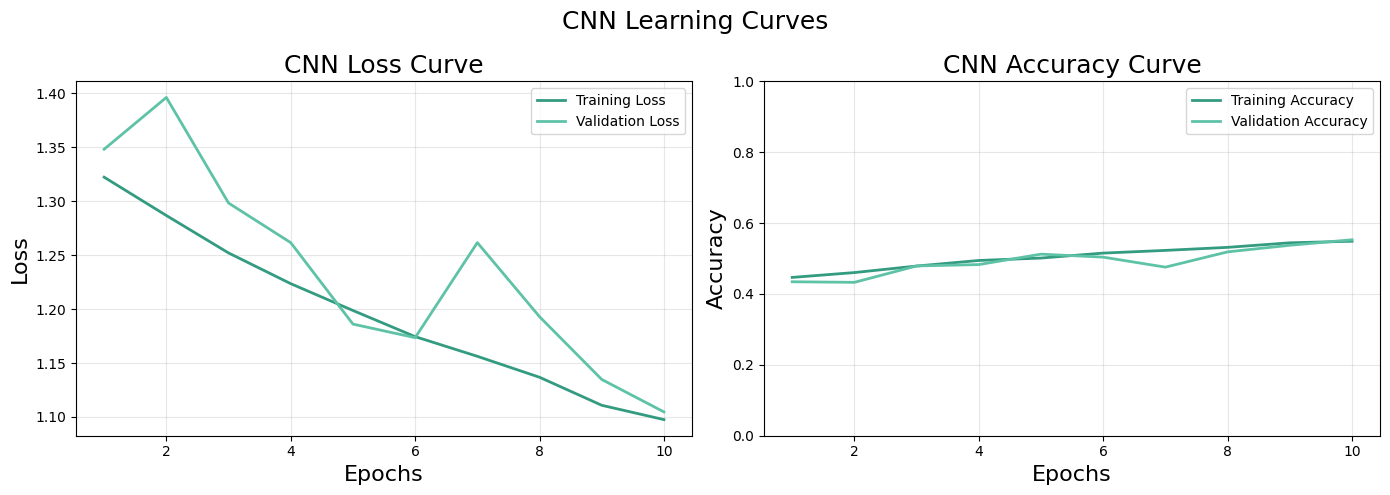

In [ ]:
# Plot the ResNet18 learning curve.
plot_learning_curve("CNN",train_losses,validation_losses,train_accuracies,validation_accuracies)

- The training loss decreases steadily from about 1.32 in the first epoch to about 1.10 by the tenth epoch.
- The validation loss fluctuates during training but shows an overall decreasing trend, reaching about 1.10 by the tenth epoch.
- Training accuracy increases gradually from about 0.44 in the first epoch to about 0.55 by the tenth epoch.
- Validation accuracy follows a similar trend and reaches about 0.55 by the tenth epoch.
- The training and validation accuracy curves remain close to each other throughout most of the epochs, indicating similar performance on training and validation data.
- The learning curves show gradual improvement, but the accuracy remains relatively low by the end of training.
- Overall, the CNN shows slow learning progress and lower classification performance compared with the other models.

In [ ]:
# Print the CNN classification report.
print_classification_report("CNN",cnn_true_labels,cnn_predicted_labels,class_names)

CNN - Classification Report
              precision    recall  f1-score   support

       Angry     0.4540    0.2431    0.3166      1522
        Fear     0.3518    0.1260    0.1856      1460
       Happy     0.5767    0.9049    0.7045      2766
         Sad     0.4951    0.4015    0.4434      1883
     Suprise     0.5837    0.7853    0.6697      1234

    accuracy                         0.5394      8865
   macro avg     0.4923    0.4922    0.4640      8865
weighted avg     0.5022    0.5394    0.4921      8865



- The CNN achieves an overall accuracy of 0.5394, indicating limited classification performance across the five emotion classes.
- The Happy class shows the strongest recall at 0.9049, with an F1-score of 0.7045.
- The Suprise class also shows relatively strong recall at 0.7853 and an F1-score of 0.6697.
- The Fear class has the lowest recall at 0.1260 and the lowest F1-score at 0.1856, indicating difficulty in correctly identifying Fear images.
- The Angry class also has a low recall of 0.2431, showing that many Angry images are not correctly identified.
- The weighted F1-score is 0.4921, which is lower than the overall accuracy and indicates uneven performance across the emotion classes.
- Overall, the CNN performs better for Happy and Suprise but has difficulty distinguishing Angry, Fear, and Sad emotions.

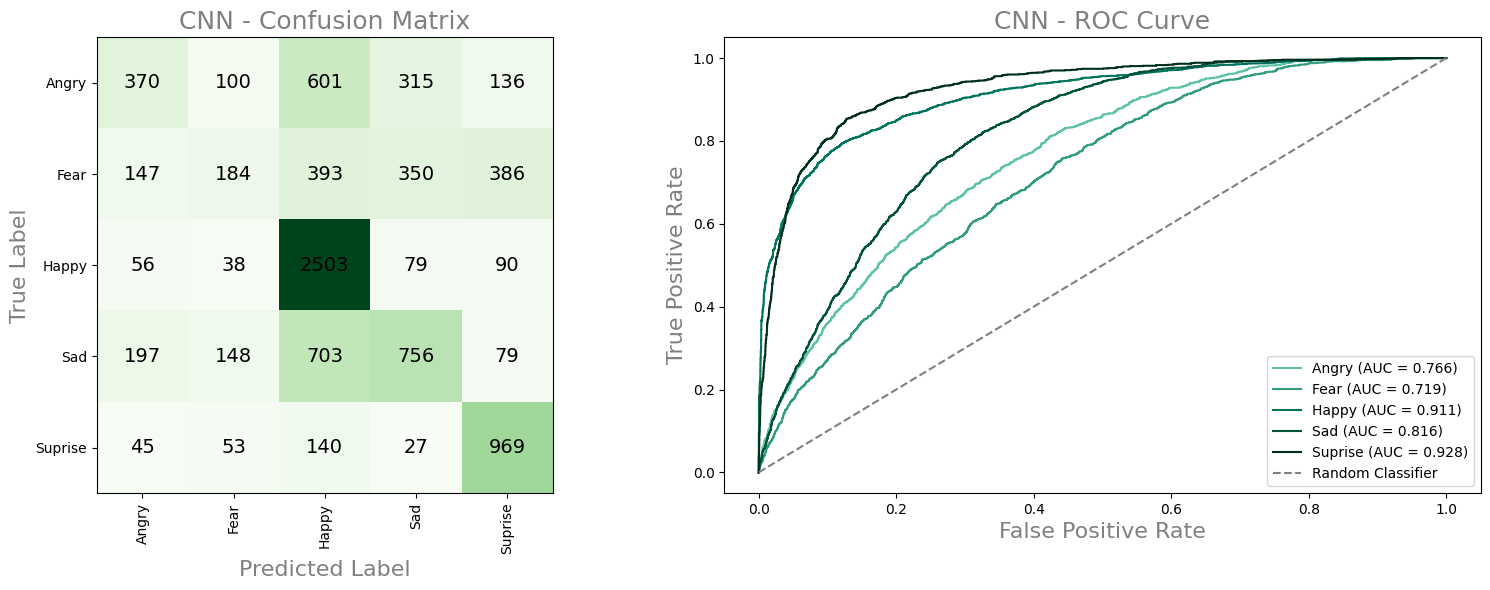

In [ ]:
# Plot the CNN confusion matrix and ROC curve.
plot_confusion_matrix_roc("CNN",cnn_true_labels,cnn_predicted_labels,cnn_predicted_probabilities,class_names)

- The confusion matrix shows that the CNN correctly classifies 2503 Happy images and 969 Suprise images.
- The Angry and Fear classes show lower numbers of correct predictions, with 370 Angry images and 184 Fear images classified correctly.
- A considerable amount of confusion is observed between Angry, Fear, Sad, and Happy classes.
- The largest misclassification is observed for Sad images, where 703 images are predicted as Happy.
- Fear images are also frequently misclassified as Happy, Sad, and Suprise.
- The ROC curves show varying class-separation performance across the five emotions.
- The AUC values range from 0.719 for Fear to 0.928 for Suprise, with Suprise showing the strongest class discrimination.
- Overall, the CNN shows good discrimination for Happy and Suprise but has difficulty distinguishing some of the other emotion classes.

### MobileNetV3 with Multi-Head Attention

MobileNetV3 is used as the backbone for feature extraction from the facial images. The extracted spatial features are converted into a sequence of feature representations and passed through **Multi-Head Self-Attention (MHA)**. The attention mechanism helps the model learn relationships between different spatial regions of the face.The attention-enhanced features are then globally pooled and passed through a fully connected layer to classify the five emotion classes.

In [ ]:
# Define MobileNetV3 with Multi-Head Attention.
class MobileNetV3MHA(nn.Module):

    def __init__(self, num_classes=5, num_heads=8):
        super().__init__()

        # Load the MobileNetV3-Large architecture.
        self.backbone = mobilenet_v3_large(weights=None)

        # Keep only the convolutional feature extraction part
        # of MobileNetV3.
        self.features = self.backbone.features

        # MobileNetV3-Large produces 960 output channels
        # before its original classifier.
        feature_dim = 960

        # Multi-Head Self-Attention.
        self.attention = nn.MultiheadAttention(embed_dim=feature_dim,num_heads=num_heads,batch_first=True)

        # Global average pooling across the spatial locations.
        self.global_pool = nn.AdaptiveAvgPool1d(1)

        # Final classification layer.
        self.classifier = nn.Linear(feature_dim,num_classes)

    def forward(self, x):

        # Extract spatial features using MobileNetV3.
        x = self.features(x)

        # Get the feature dimensions.
        batch_size, channels, height, width = x.shape

        # Convert spatial feature map into a sequence.
        # Shape: [Batch, Channels, Height, Width] into [Batch, Height × Width, Channels]
        x = x.flatten(2).transpose(1, 2)

        # Apply Multi-Head Self-Attention.
        attention_output, _ = self.attention(x,x,x)

        # Convert [Batch, Spatial Locations, Channels] into [Batch, Channels, Spatial Locations]
        attention_output = attention_output.transpose(1, 2)

        # Global average pooling.
        attention_output = self.global_pool(attention_output)

        # Remove the final dimension.
        attention_output = attention_output.squeeze(-1)

        # Classification output.
        output = self.classifier(attention_output)
        return output

In [ ]:
# Create the MobileNetV3-MHA model.
mobilenet_mha_model = MobileNetV3MHA(num_classes=5,num_heads=8)

# Move the model to the available device.
mobilenet_mha_model = mobilenet_mha_model.to(device)

print("Device:", device)
print("MobileNetV3-MHA model created successfully.")

Device: cuda
MobileNetV3-MHA model created successfully.


In [ ]:
# Get one batch from the training DataLoader.
images, labels = next(iter(train_loader))

# Move the images to the selected device.
images = images.to(device)

# Disable gradient calculation for the architecture test.
with torch.no_grad():

    # Pass the images through MobileNetV3-MHA.
    outputs = mobilenet_mha_model(images)

# Display the input and output shapes.
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 224, 224])
Output shape: torch.Size([64, 5])


In [ ]:
# Define the loss function for five-class classification.
criterion_mha = nn.CrossEntropyLoss()

# Define the Adam optimizer.
optimizer_mha = optim.Adam(mobilenet_mha_model.parameters(),lr=0.001)

# Reduce the learning rate when validation loss stops improving.
scheduler_mha = optim.lr_scheduler.ReduceLROnPlateau(
optimizer_mha,mode="min",factor=0.5,patience=2)

print("Loss function:", criterion_mha)
print("Optimizer:", optimizer_mha)
print("Learning rate:", optimizer_mha.param_groups[0]["lr"])
print("Scheduler:", scheduler_mha)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001
Scheduler: <torch.optim.lr_scheduler.ReduceLROnPlateau object at 0x7bee487178c0>


#### Model Training

In [ ]:
# Number of training epochs.
num_epochs_mha = 10

# Store training and validation metrics.
train_losses_mha = []
train_accuracies_mha = []
validation_losses_mha = []
validation_accuracies_mha = []

# Track the best validation loss.
best_validation_loss_mha = float("inf")

# Store the weights of the best model.
best_model_weights_mha = copy.deepcopy(mobilenet_mha_model.state_dict())

for epoch in range(num_epochs_mha):
    # Training
    mobilenet_mha_model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    # Display training progress.
    progress_bar = tqdm(train_loader,desc=f"Epoch {epoch + 1}/{num_epochs_mha} - Training",leave=True)

    for images, labels in progress_bar:

        # Move images and labels to the selected device.
        images = images.to(device)
        labels = labels.to(device)

        # Clear previously calculated gradients.
        optimizer_mha.zero_grad()

        # Forward pass.
        outputs = mobilenet_mha_model(images)

        # Calculate training loss.
        loss = criterion_mha(outputs, labels)

        # Backpropagation.
        loss.backward()

        # Update model parameters.
        optimizer_mha.step()

        # Add batch loss.
        running_loss += loss.item() * images.size(0)

        # Calculate predictions.
        predictions = torch.argmax(outputs, dim=1)

        # Count correct predictions.
        correct_predictions += (predictions == labels).sum().item()

        # Add number of samples.
        total_samples += labels.size(0)

        # Calculate current metrics.
        current_loss = running_loss / total_samples
        current_accuracy = correct_predictions / total_samples

        # Update progress bar.
        progress_bar.set_postfix(loss=f"{current_loss:.4f}",accuracy=f"{current_accuracy:.4f}")

    # Calculate final training metrics.
    epoch_train_loss = running_loss / total_samples
    epoch_train_accuracy = correct_predictions / total_samples

    # Validation
    mobilenet_mha_model.eval()

    running_validation_loss = 0.0
    correct_validation_predictions = 0
    total_validation_samples = 0

    validation_bar = tqdm(validation_loader,desc=f"Epoch {epoch + 1}/{num_epochs_mha} - Validation",leave=True)

    with torch.no_grad():

        for images, labels in validation_bar:

            # Move images and labels to the selected device.
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass.
            outputs = mobilenet_mha_model(images)

            # Calculate validation loss.
            loss = criterion_mha(outputs, labels)

            # Add validation loss.
            running_validation_loss += (loss.item() * images.size(0))

            # Calculate predictions.
            predictions = torch.argmax(outputs, dim=1)

            # Count correct predictions.
            correct_validation_predictions += (predictions == labels).sum().item()

            # Add number of samples.
            total_validation_samples += labels.size(0)

            # Calculate current validation metrics.
            current_validation_loss = (running_validation_loss /total_validation_samples)

            current_validation_accuracy = (correct_validation_predictions /total_validation_samples)

            # Update validation progress bar.
            validation_bar.set_postfix(loss=f"{current_validation_loss:.4f}",accuracy=f"{current_validation_accuracy:.4f}")

    # Calculate final validation metrics.
    epoch_validation_loss = (running_validation_loss /total_validation_samples)

    epoch_validation_accuracy = (correct_validation_predictions /total_validation_samples)

    # Store metrics.
    train_losses_mha.append(epoch_train_loss)
    train_accuracies_mha.append(epoch_train_accuracy)

    validation_losses_mha.append(epoch_validation_loss)
    validation_accuracies_mha.append(epoch_validation_accuracy)

    # Update learning-rate scheduler.
    scheduler_mha.step(epoch_validation_loss)

    # Save the model when validation loss improves.
    if epoch_validation_loss < best_validation_loss_mha:

        best_validation_loss_mha = epoch_validation_loss

        best_model_weights_mha = copy.deepcopy(
            mobilenet_mha_model.state_dict()
        )

        torch.save(
            best_model_weights_mha,
            "best_mobilenet_v3_mha_model.pth"
        )

        best_model_status = "Saved"

    else:
        best_model_status = "Not saved"

    # Get current learning rate.
    current_learning_rate = (optimizer_mha.param_groups[0]["lr"])

    # Display final epoch results.
    print(f"Training Loss:       {epoch_train_loss:.4f}")
    print(f"Training Accuracy:   {epoch_train_accuracy:.4f}")
    print(f"Validation Loss:     {epoch_validation_loss:.4f}")
    print(f"Validation Accuracy: {epoch_validation_accuracy:.4f}")
    print(f"Learning Rate:       {current_learning_rate:.6f}")

Epoch 1/10 - Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch 1/10 - Validation:   0%|          | 0/139 [00:00<?, ?it/s]

Training Loss:       1.2620
Training Accuracy:   0.4705
Validation Loss:     2.1186
Validation Accuracy: 0.2939
Learning Rate:       0.001000


Epoch 2/10 - Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch 2/10 - Validation:   0%|          | 0/139 [00:00<?, ?it/s]

Training Loss:       1.0709
Training Accuracy:   0.5572
Validation Loss:     1.1218
Validation Accuracy: 0.5901
Learning Rate:       0.001000


... (20 outputs left out)

Training Loss:       0.3247
Training Accuracy:   0.8841
Validation Loss:     0.6209
Validation Accuracy: 0.7999
Learning Rate:       0.000500


Epoch 10/10 - Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch 10/10 - Validation:   0%|          | 0/139 [00:00<?, ?it/s]

Training Loss:       0.2269
Training Accuracy:   0.9212
Validation Loss:     0.5374
Validation Accuracy: 0.8430
Learning Rate:       0.000500


#### Model Evaluation

In [ ]:
class_names = ["Angry","Fear","Happy","Sad","Suprise"]

mobilenet_mha_metrics, mobilenet_mha_true_labels, mobilenet_mha_predicted_labels, mobilenet_mha_probabilities = calculate_metrics(
    mobilenet_mha_model,
    test_loader,
    device,
    class_names
)

In [ ]:
# Print MobileNetV3-MHA evaluation metrics.
print("MobileNetV3-MHA Evaluation Metrics")
print("=" * 50)

print(f"Accuracy:    {mobilenet_mha_metrics['Accuracy']:.4f}")
print(f"Precision:   {mobilenet_mha_metrics['Precision']:.4f}")
print(f"Recall:      {mobilenet_mha_metrics['Recall']:.4f}")
print(f"F1-Score:    {mobilenet_mha_metrics['F1-Score']:.4f}")
print(f"Brier Score: {mobilenet_mha_metrics['Brier Score']:.4f}")

MobileNetV3-MHA Evaluation Metrics
Accuracy:    0.8450
Precision:   0.8456
Recall:      0.8450
F1-Score:    0.8446
Brier Score: 0.2321


- MobileNetV3-MHA achieves an Accuracy of 0.8450, showing good overall classification performance.
- The Precision is 0.8456, indicating that the model provides reliable predictions across the emotion classes.
- The Recall is 0.8450, showing that the model identifies a good proportion of the actual emotion classes.
- The F1-Score is 0.8446, indicating a balanced performance between Precision and Recall.
- The Brier Score is 0.2321, showing the quality of the model's predicted probabilities.
- Overall, the evaluation metrics indicate that MobileNetV3-MHA provides consistent performance across the five facial emotion classes.

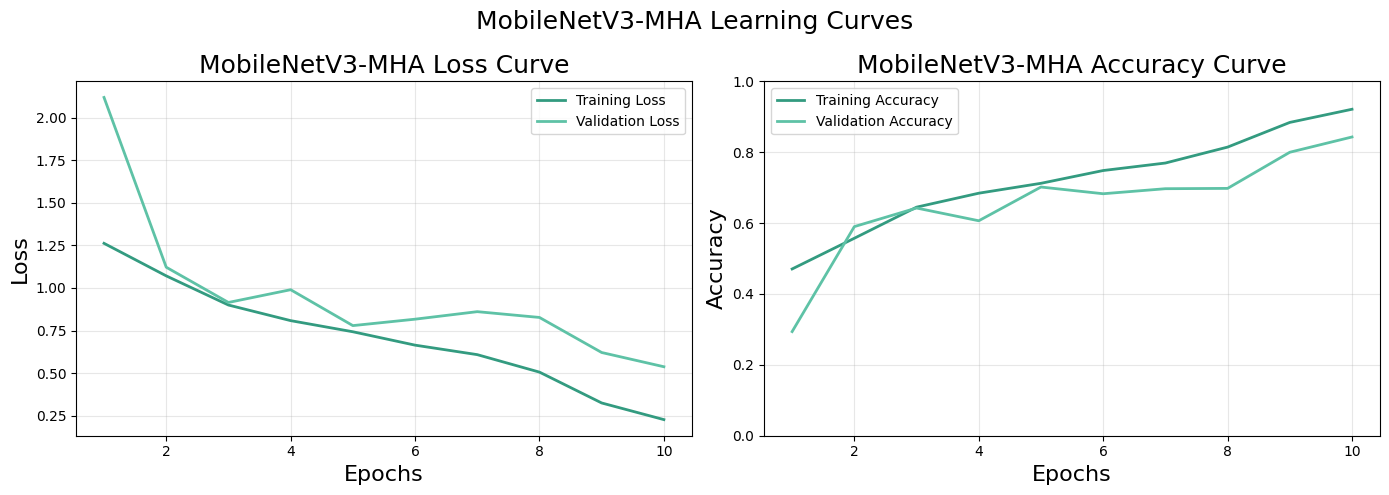

In [ ]:
# Plot MobileNetV3-MHA learning curve.
plot_learning_curve("MobileNetV3-MHA",train_losses_mha,validation_losses_mha,train_accuracies_mha,validation_accuracies_mha)

- The training loss decreases steadily from about 1.26 in the first epoch to about 0.22 by the tenth epoch, showing that the model is learning from the training data.
- The validation loss decreases overall from about 2.12 in the first epoch to about 0.54 by the tenth epoch, although some fluctuations are observed during training.
- Training accuracy increases gradually from about 0.47 in the first epoch to about 0.92 by the tenth epoch.
- Validation accuracy improves from about 0.29 in the first epoch to about 0.84 by the tenth epoch.
- The validation accuracy becomes relatively stable around the middle epochs and improves again during the later epochs.
- The increasing gap between training and validation accuracy in the later epochs indicates some overfitting, although the validation performance continues to improve.
- Overall, the learning curves show that MobileNetV3-MHA learns progressively and achieves stable validation performance by the later epochs.

In [ ]:
# Print MobileNetV3-MHA classification report.
print_classification_report("MobileNetV3-MHA",mobilenet_mha_true_labels,mobilenet_mha_predicted_labels, class_names)

MobileNetV3-MHA - Classification Report
              precision    recall  f1-score   support

       Angry     0.7440    0.8325    0.7857      1522
        Fear     0.7562    0.6884    0.7207      1460
       Happy     0.9452    0.9483    0.9468      2766
         Sad     0.8210    0.7987    0.8097      1883
     Suprise     0.8907    0.8849    0.8878      1234

    accuracy                         0.8450      8865
   macro avg     0.8314    0.8306    0.8301      8865
weighted avg     0.8456    0.8450    0.8446      8865



- MobileNetV3-MHA achieves an overall accuracy of 0.8450, showing good classification performance across the five emotion classes.
- The Happy class shows the strongest results, with precision of 0.9452, recall of 0.9483, and F1-score of 0.9468.
- The Suprise class also performs well, with an F1-score of 0.8878.
- The Fear class has the lowest recall at 0.6884 and the lowest F1-score at 0.7207, indicating more difficulty in correctly identifying Fear images.
- The Angry class has a recall of 0.8325, while its precision is lower at 0.7440.
- The weighted F1-score is 0.8446, showing consistent overall performance across the dataset.
- Overall, MobileNetV3-MHA performs well on Happy and Suprise, while Fear remains the most challenging emotion class for the model.

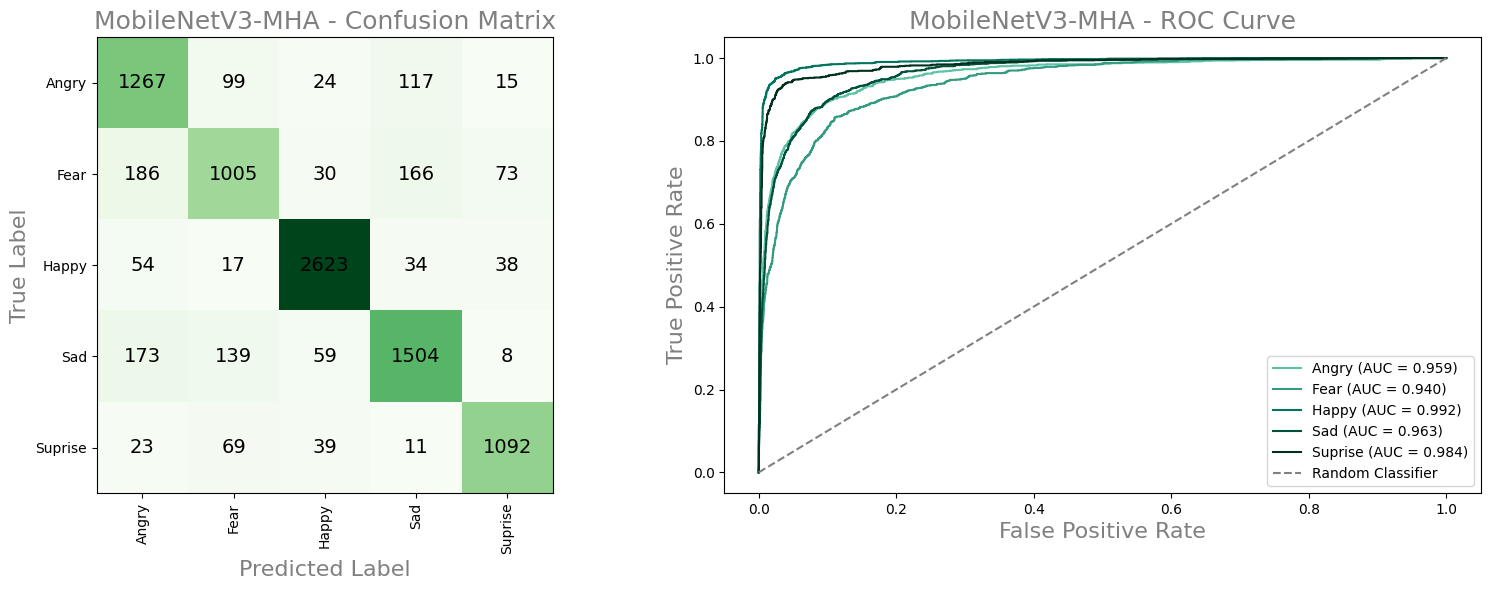

In [ ]:
# Plot MobileNetV3-MHA confusion matrix and ROC curve.
plot_confusion_matrix_roc("MobileNetV3-MHA",mobilenet_mha_true_labels, mobilenet_mha_predicted_labels,mobilenet_mha_probabilities, class_names)

- The confusion matrix shows that MobileNetV3-MHA correctly classifies a large number of images across all five emotion classes.
- The Happy class has the highest number of correct predictions, with 2623 images classified correctly.
- Angry and Suprise also show strong classification results, with 1267 and 1092 correct predictions respectively.
- The main misclassifications are observed between Fear and other classes, particularly Fear images predicted as Angry (186) and Sad (166).
- Sad images are also sometimes predicted as Angry (173) and Fear (139), showing some confusion between these emotion classes.
- The ROC curves are positioned well above the random classifier line, indicating good class discrimination.
- The AUC values range from 0.940 for Fear to 0.992 for Happy, with Happy showing the strongest class discrimination.
- Overall, MobileNetV3-MHA demonstrates good classification and class-separation performance across the five facial emotion classes.

### ResNet18 Model

ResNet18 is a convolutional neural network based on the Residual Network architecture. In this project, a pretrained ResNet18 model is used for human facial emotion recognition. The final fully connected layer of the pretrained ResNet18 model is replaced to classify the five facial emotion categories in the dataset. The model uses the same preprocessing pipeline, training dataset, and validation dataset defined for the facial emotion recognition task.


In [ ]:
# Load the pretrained ResNet18 model.
resnet_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Get the number of input features of the final classification layer.
num_features = resnet_model.fc.in_features

# Replace the final fully connected layer for the five emotion classes.
resnet_model.fc = nn.Linear(num_features,len(class_names))

# Move the model to the selected device.
resnet_model = resnet_model.to(device)

# Display model information.
print("Model: ResNet18")
print("Number of classes:", len(class_names))
print("Classes:", class_names)
print("Device:", device)

Model: ResNet18
Number of classes: 5
Classes: ['Angry', 'Fear', 'Happy', 'Sad', 'Suprise']
Device: cuda


In [ ]:
# Get one batch of images from the training DataLoader.
images, labels = next(iter(train_loader))

# Move the images to the selected device.
images = images.to(device)

# Disable gradient calculation for the architecture test.
with torch.no_grad():

    # Pass the images through ResNet18.
    outputs = resnet_model(images)

# Display the input and output shapes.
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 224, 224])
Output shape: torch.Size([64, 5])


In [ ]:
# Define the loss function for five-class emotion classification.
criterion_resnet = nn.CrossEntropyLoss()

# Define the Adam optimizer.
optimizer_resnet = optim.Adam(resnet_model.parameters(),lr=0.0001)

# Reduce the learning rate when validation loss stops improving.
scheduler_resnet = optim.lr_scheduler.ReduceLROnPlateau(optimizer_resnet,mode="min",factor=0.5,patience=2)

# Display the training configuration.
print("Loss function:", criterion_resnet)
print("Optimizer:", optimizer_resnet)
print("Learning rate:", optimizer_resnet.param_groups[0]["lr"])
print("Scheduler:", scheduler_resnet)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.0001
Scheduler: <torch.optim.lr_scheduler.ReduceLROnPlateau object at 0x7bee53ff3bc0>


#### Model Training

In [ ]:
# Number of training epochs.
num_epochs_resnet = 5

# Store training and validation metrics.
train_losses_resnet = []
train_accuracies_resnet = []
validation_losses_resnet = []
validation_accuracies_resnet = []

# Track the best validation loss.
best_validation_loss_resnet = float("inf")

# Store the weights of the best model.
best_model_weights_resnet = copy.deepcopy(resnet_model.state_dict())

for epoch in range(num_epochs_resnet):

    # Training
    resnet_model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    # Display training progress.
    progress_bar = tqdm(train_loader,desc=f"Epoch {epoch + 1}/{num_epochs_resnet} - Training",leave=True)

    for images, labels in progress_bar:

        # Move images and labels to the selected device.
        images = images.to(device)
        labels = labels.to(device)

        # Clear previously calculated gradients.
        optimizer_resnet.zero_grad()

        # Forward pass.
        outputs = resnet_model(images)

        # Calculate training loss.
        loss = criterion_resnet(outputs, labels)

        # Backpropagation.
        loss.backward()

        # Update model parameters.
        optimizer_resnet.step()

        # Add batch loss.
        running_loss += loss.item() * images.size(0)

        # Calculate predictions.
        predictions = torch.argmax(outputs, dim=1)

        # Count correct predictions.
        correct_predictions += (predictions == labels).sum().item()

        # Add number of samples.
        total_samples += labels.size(0)

        # Calculate current metrics.
        current_loss = running_loss / total_samples
        current_accuracy = correct_predictions / total_samples

        # Update progress bar.
        progress_bar.set_postfix(loss=f"{current_loss:.4f}",accuracy=f"{current_accuracy:.4f}")

    # Calculate final training metrics.
    epoch_train_loss = running_loss / total_samples
    epoch_train_accuracy = correct_predictions / total_samples

    # Validation
    resnet_model.eval()

    running_validation_loss = 0.0
    correct_validation_predictions = 0
    total_validation_samples = 0

    validation_bar = tqdm(validation_loader,desc=f"Epoch {epoch + 1}/{num_epochs_resnet} - Validation",leave=True)

    with torch.no_grad():

        for images, labels in validation_bar:

            # Move images and labels to the selected device.
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass.
            outputs = resnet_model(images)

            # Calculate validation loss.
            loss = criterion_resnet(outputs, labels)

            # Add validation loss.
            running_validation_loss += loss.item() * images.size(0)

            # Calculate predictions.
            predictions = torch.argmax(outputs, dim=1)

            # Count correct predictions.
            correct_validation_predictions += (predictions == labels).sum().item()

            # Add number of samples.
            total_validation_samples += labels.size(0)

            # Calculate current validation metrics.
            current_validation_loss = running_validation_loss / total_validation_samples
            current_validation_accuracy = correct_validation_predictions / total_validation_samples

            # Update validation progress bar.
            validation_bar.set_postfix(loss=f"{current_validation_loss:.4f}",accuracy=f"{current_validation_accuracy:.4f}")

    # Calculate final validation metrics.
    epoch_validation_loss = running_validation_loss / total_validation_samples
    epoch_validation_accuracy = correct_validation_predictions / total_validation_samples

    # Store metrics.
    train_losses_resnet.append(epoch_train_loss)
    train_accuracies_resnet.append(epoch_train_accuracy)
    validation_losses_resnet.append(epoch_validation_loss)
    validation_accuracies_resnet.append(epoch_validation_accuracy)

    # Update learning-rate scheduler.
    scheduler_resnet.step(epoch_validation_loss)

    # Save the model when validation loss improves.
    if epoch_validation_loss < best_validation_loss_resnet:

        best_validation_loss_resnet = epoch_validation_loss

        best_model_weights_resnet = copy.deepcopy(resnet_model.state_dict())

        torch.save(
            best_model_weights_resnet,
            "/kaggle/working/best_resnet18_model.pth"
        )

        best_model_status = "Saved"

    else:
        best_model_status = "Not saved"

    # Get current learning rate.
    current_learning_rate = optimizer_resnet.param_groups[0]["lr"]

    # Display final epoch results.
    print(f"Training Loss:       {epoch_train_loss:.4f}")
    print(f"Training Accuracy:   {epoch_train_accuracy:.4f}")
    print(f"Validation Loss:     {epoch_validation_loss:.4f}")
    print(f"Validation Accuracy: {epoch_validation_accuracy:.4f}")
    print(f"Learning Rate:       {current_learning_rate:.6f}")

Epoch 1/5 - Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch 1/5 - Validation:   0%|          | 0/139 [00:00<?, ?it/s]

Training Loss:       0.7654
Training Accuracy:   0.7022
Validation Loss:     0.5775
Validation Accuracy: 0.7816
Learning Rate:       0.000100


Epoch 2/5 - Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch 2/5 - Validation:   0%|          | 0/139 [00:00<?, ?it/s]

Training Loss:       0.3583
Training Accuracy:   0.8746
Validation Loss:     0.4117
Validation Accuracy: 0.8622
Learning Rate:       0.000100


... (5 outputs left out)

Training Loss:       0.0766
Training Accuracy:   0.9787
Validation Loss:     0.3857
Validation Accuracy: 0.8972
Learning Rate:       0.000100


Epoch 5/5 - Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch 5/5 - Validation:   0%|          | 0/139 [00:00<?, ?it/s]

Training Loss:       0.0551
Training Accuracy:   0.9841
Validation Loss:     0.4033
Validation Accuracy: 0.8986
Learning Rate:       0.000100


#### Model Evaluation

In [ ]:
# Calculate ResNet18 evaluation metrics on the test dataset.
resnet_metrics, resnet_true_labels, resnet_predicted_labels, resnet_probabilities = calculate_metrics(resnet_model,test_loader,device,class_names)

In [ ]:
# Print ResNet18 evaluation metrics.
print("ResNet18 Evaluation Metrics")
print("=" * 50)

print(f"Accuracy:    {resnet_metrics['Accuracy']:.4f}")
print(f"Precision:   {resnet_metrics['Precision']:.4f}")
print(f"Recall:      {resnet_metrics['Recall']:.4f}")
print(f"F1-Score:    {resnet_metrics['F1-Score']:.4f}")
print(f"Brier Score: {resnet_metrics['Brier Score']:.4f}")

ResNet18 Evaluation Metrics
Accuracy:    0.8992
Precision:   0.9029
Recall:      0.8992
F1-Score:    0.8999
Brier Score: 0.1633


- ResNet18 achieves an Accuracy of 0.8992, indicating strong overall classification performance.
- The Precision is 0.9029, showing that the model provides reliable predictions across the emotion classes.
- The Recall is 0.8992, indicating that the model successfully identifies most of the actual emotion classes.
- The F1-Score is 0.8999, showing a good balance between Precision and Recall.
- The Brier Score is 0.1633, which indicates good probability calibration compared with the other models.
- Overall, the evaluation metrics show that ResNet18 provides strong and balanced performance for facial emotion classification.

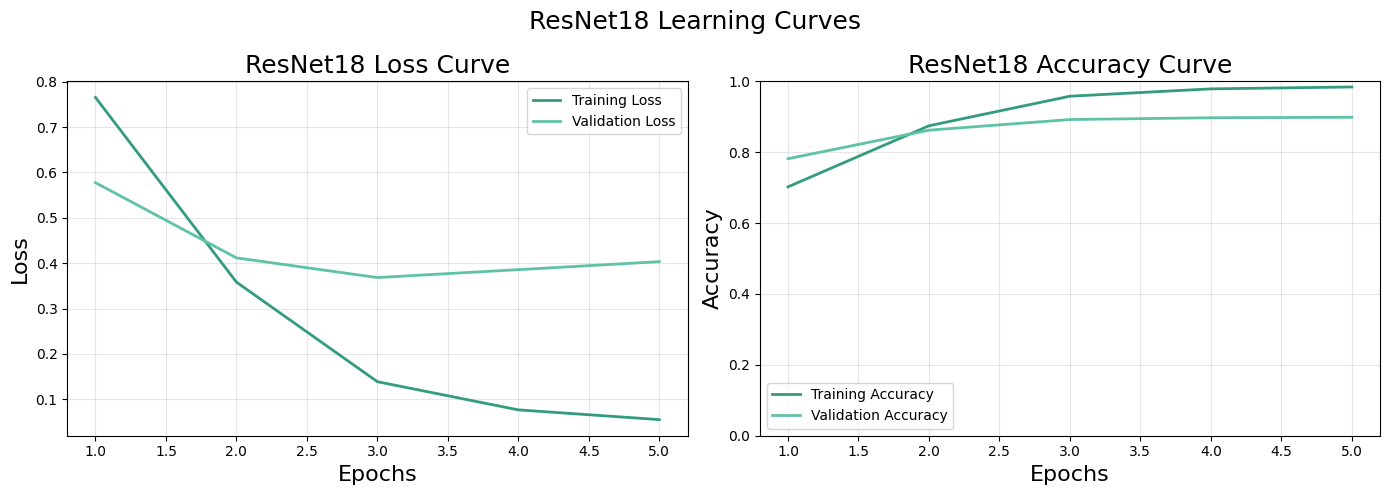

In [ ]:
# Plot the ResNet18 learning curve.
plot_learning_curve("ResNet18",train_losses_resnet,validation_losses_resnet,train_accuracies_resnet,validation_accuracies_resnet)

- The training loss decreases steadily from about 0.76 in the first epoch to about 0.05 by the fifth epoch.
- The validation loss also decreases during training, reaching its lowest value of about 0.37 in the third epoch before showing a small increase in the following epochs.
- Training accuracy increases consistently across the epochs and reaches about 0.98 by the fifth epoch.
- Validation accuracy improves from about 0.78 in the first epoch to about 0.90 by the third epoch and remains nearly stable afterward.
- The training and validation accuracy curves remain relatively close after the third epoch, indicating stable model learning.
- The increase in validation loss after the third epoch, while validation accuracy remains stable, suggests that further training provides limited improvement.

In [ ]:
# Print the ResNet18 classification report.
print_classification_report("ResNet18",resnet_true_labels,resnet_predicted_labels,class_names)

ResNet18 - Classification Report
              precision    recall  f1-score   support

       Angry     0.8929    0.8712    0.8819      1522
        Fear     0.7628    0.8808    0.8175      1460
       Happy     0.9614    0.9646    0.9630      2766
         Sad     0.9086    0.8290    0.8670      1883
     Suprise     0.9409    0.9157    0.9281      1234

    accuracy                         0.8992      8865
   macro avg     0.8933    0.8923    0.8915      8865
weighted avg     0.9029    0.8992    0.8999      8865



- ResNet18 achieves strong classification performance across the five facial emotion classes.
- The Happy class has the strongest results, with precision of 0.9614, recall of 0.9646, and F1-score of 0.9630.
- The Suprise class also shows strong performance, with an F1-score of 0.9281.
- The Fear class has the lowest precision at 0.7628, although its recall is relatively high at 0.8808.
- The Sad class has a precision of 0.9086 and recall of 0.8290, indicating that some Sad images are being predicted as other emotions.
- The overall accuracy is 0.8992, with a weighted F1-score of 0.8999.
- Overall, the classification report shows that ResNet18 provides consistent performance across the five emotion classes, with particularly strong results for Happy and Suprise.

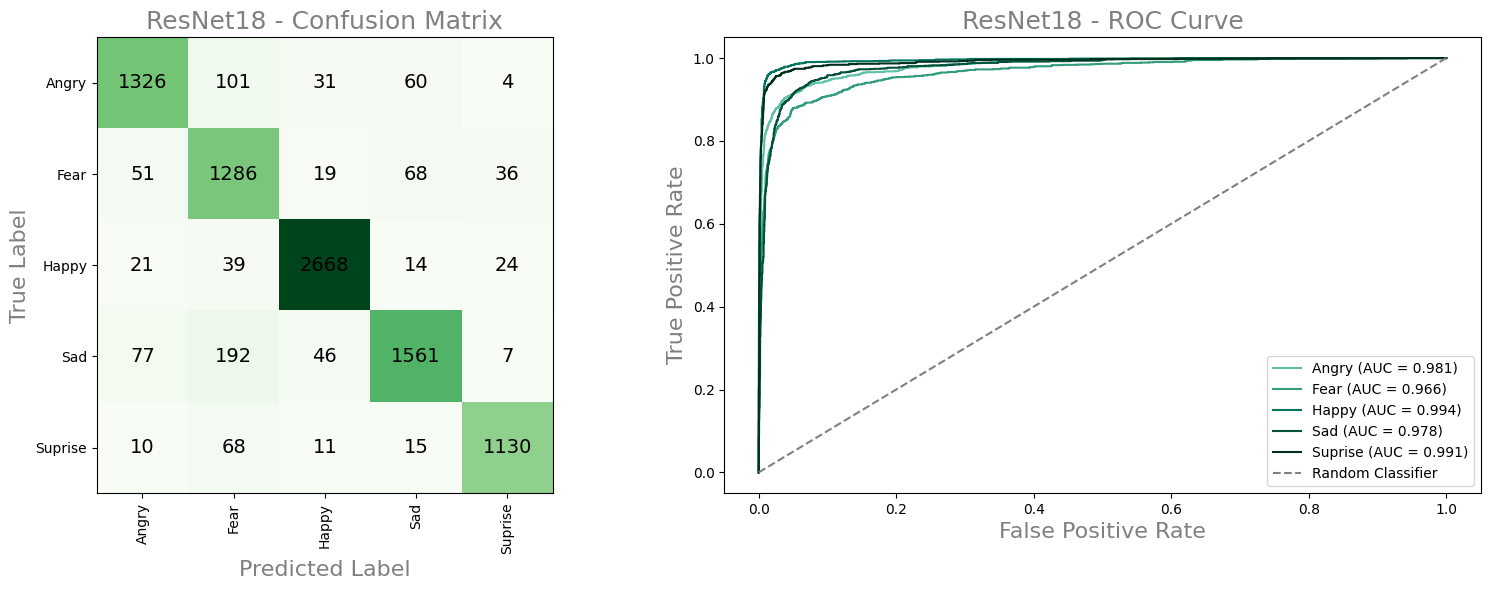

In [ ]:
# Plot the ResNet18 confusion matrix and ROC curve.
plot_confusion_matrix_roc("ResNet18",resnet_true_labels,resnet_predicted_labels,resnet_probabilities,class_names)

- The confusion matrix shows that ResNet18 correctly classifies most images across all five emotion classes.
- The Happy class has the highest number of correct predictions, with 2668 images classified correctly.
- The Angry, Fear, Sad, and Suprise classes also show strong diagonal values, indicating good classification performance for these emotions.
- The main misclassifications occur between Sad and Fear, with 192 Sad images predicted as Fear and 68 Fear images predicted as Sad.
- The ROC curves are close to the top-left corner, indicating strong class discrimination by ResNet18.
- The AUC values are high for all five emotions, ranging from 0.966 for Fear to 0.994 for Happy.
- Overall, the confusion matrix and ROC curves indicate that ResNet18 performs well in distinguishing the five facial emotion classes.

## Model Comparison

The final three models are compared using the same unseen test set. Metric values are calculated directly from each model's actual predictions so no results are entered manually.

In [ ]:
# Create a DataFrame containing the evaluation results of all three models.
model_results = pd.DataFrame({
    "Model": ["CNN", "MobileNetV3-MHA", "ResNet18"],
    "Accuracy": [cnn_metrics["Accuracy"],mobilenet_mha_metrics["Accuracy"],resnet_metrics["Accuracy"]],
    "Precision": [cnn_metrics["Precision"],mobilenet_mha_metrics["Precision"],resnet_metrics["Precision"]],
    "Recall": [cnn_metrics["Recall"],mobilenet_mha_metrics["Recall"],resnet_metrics["Recall"]],
    "F1-Score": [cnn_metrics["F1-Score"], mobilenet_mha_metrics["F1-Score"],resnet_metrics["F1-Score"] ],
    "Brier Score": [ cnn_metrics["Brier Score"],mobilenet_mha_metrics["Brier Score"],resnet_metrics["Brier Score"]]
})

# Display the comparison DataFrame.
display(model_results)

,Model,Accuracy,Precision,Recall,F1-Score,Brier Score
0,CNN,0.539425,0.502248,0.539425,0.492131,0.572065
1,MobileNetV3-MHA,0.845008,0.845560,0.845008,0.844561,0.232096
2,ResNet18,0.899154,0.902874,0.899154,0.899880,0.163291


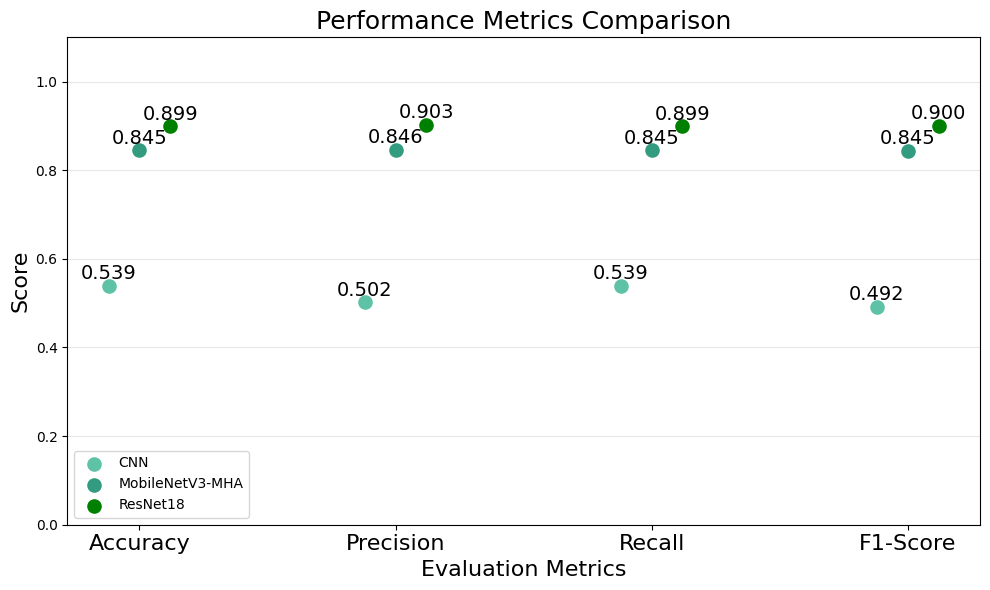

In [ ]:
# Store the names of the models used for comparison.
model_names = ["CNN", "MobileNetV3-MHA", "ResNet18"]

# Store the performance metrics for each model.
metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]

# Store the metric values for each model.
metric_values = {
    "CNN": [
        cnn_metrics["Accuracy"],
        cnn_metrics["Precision"],
        cnn_metrics["Recall"],
        cnn_metrics["F1-Score"]
    ],
    "MobileNetV3-MHA": [
        mobilenet_mha_metrics["Accuracy"],
        mobilenet_mha_metrics["Precision"],
        mobilenet_mha_metrics["Recall"],
        mobilenet_mha_metrics["F1-Score"]
    ],
    "ResNet18": [
        resnet_metrics["Accuracy"],
        resnet_metrics["Precision"],
        resnet_metrics["Recall"],
        resnet_metrics["F1-Score"]
    ]
}

# Create positions for the metrics on the x-axis.
x = np.arange(len(metric_names))

# Define small offsets so that the model points remain separated.
model_offsets = [-0.12, 0, 0.12]

# Keep the existing colours for CNN and MobileNetV3-MHA and use green for ResNet18.
model_colors = [plot_colors[0], plot_colors[1], "#008000"]

# Create a new figure for the performance comparison.
plt.figure(figsize=figure_size)

# Plot the metric values for each model.
for index, model_name in enumerate(model_names):

    # Get the metric values for the current model.
    values = metric_values[model_name]

    # Create the x positions for the current model.
    positions = x + model_offsets[index]

    # Plot the metric values as points.
    plt.scatter(positions, values, s=90, color=model_colors[index], label=model_name)

    # Display the exact value next to each point.
    for position, value in zip(positions, values):
        plt.text(position, value + 0.015, f"{value:.3f}", ha="center", fontsize=annotation_font_size)

# Set the metric names on the x-axis.
plt.xticks(x, metric_names, fontsize=axis_font_size)

# Set the label for the x-axis.
plt.xlabel("Evaluation Metrics", fontsize=axis_font_size)

# Set the label for the y-axis.
plt.ylabel("Score", fontsize=axis_font_size)

# Set the title of the comparison plot.
plt.title("Performance Metrics Comparison", fontsize=title_font_size)

# Set the score range for the comparison.
plt.ylim(0, 1.1)

# Display the model legend.
plt.legend()

# Add a light grid for easier comparison.
plt.grid(axis="y", alpha=0.3)

# Adjust the plot layout.
plt.tight_layout()

# Display the comparison plot.
plt.show()

- CNN shows the lowest overall performance among the three models, with Accuracy and Recall at 0.539, Precision at 0.502, and F1-Score at 0.492.
- MobileNetV3-MHA shows a clear improvement over CNN, with Accuracy at 0.845, Precision at 0.846, Recall at 0.845, and F1-Score at 0.845.
- ResNet18 achieves the highest values across all four metrics, with Accuracy at 0.899, Precision at 0.903, Recall at 0.899, and F1-Score at 0.900.
- The results show that ResNet18 provides the strongest overall classification performance among the three models in this comparison.

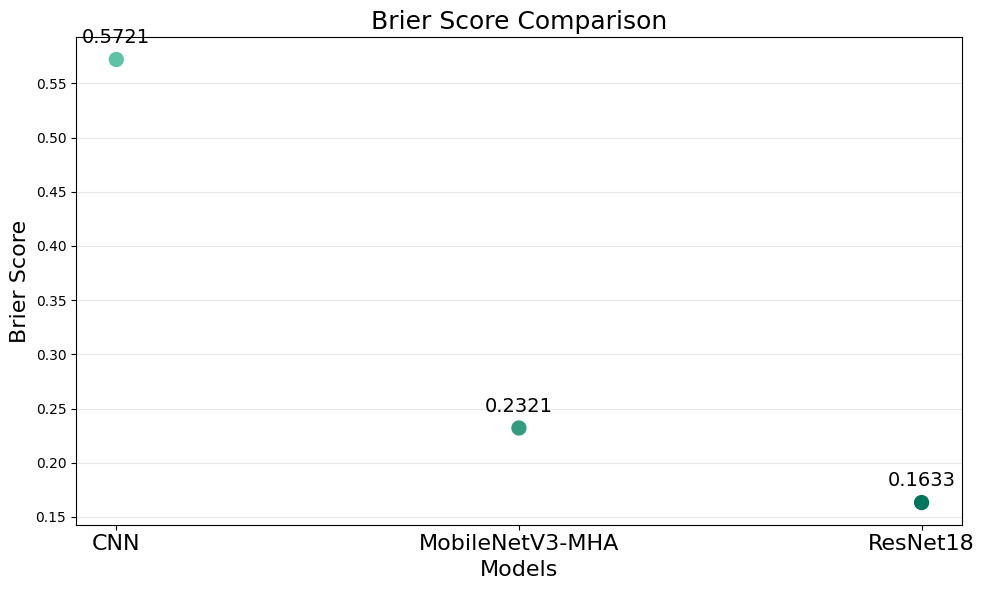

In [ ]:
# Store the Brier Score values for the three models.
brier_values = [
    cnn_metrics["Brier Score"],
    mobilenet_mha_metrics["Brier Score"],
    resnet_metrics["Brier Score"]
]

# Create positions for the models on the x-axis.
x = np.arange(len(model_names))

# Create a new figure for the Brier Score comparison.
plt.figure(figsize=figure_size)

# Plot the Brier Scores as individual points.
plt.scatter(x, brier_values, s=100, color=plot_colors[:3])

# Display the exact Brier Score value next to each point.
for position, value in zip(x, brier_values):
    plt.text(position, value + 0.015, f"{value:.4f}", ha="center", fontsize=annotation_font_size)

# Set the model names on the x-axis.
plt.xticks(x, model_names, fontsize=axis_font_size)

# Set the label for the x-axis.
plt.xlabel("Models", fontsize=axis_font_size)

# Set the label for the y-axis.
plt.ylabel("Brier Score", fontsize=axis_font_size)

# Set the title of the comparison plot.
plt.title("Brier Score Comparison", fontsize=title_font_size)

# Add a light grid for easier comparison.
plt.grid(axis="y", alpha=0.3)

# Adjust the plot layout.
plt.tight_layout()

# Display the Brier Score comparison plot.
plt.show()

- The Brier Score is highest for CNN at 0.5721.
- MobileNetV3-MHA has a lower Brier Score of 0.2321 compared with CNN.
- ResNet18 has the lowest Brier Score at 0.1633 among the three models.
- Since a lower Brier Score indicates better probability calibration, ResNet18 shows the best calibration in this comparison.

In [ ]:
# Select the model that will be used for deployment in the web application.
deployment_model_name = "ResNet18"

# Select the corresponding trained model based on the chosen model name.
if deployment_model_name == "CNN":
    deployment_model = cnn_model
elif deployment_model_name == "MobileNetV3-MHA":
    deployment_model = mobilenet_mha_model
elif deployment_model_name == "ResNet18":
    deployment_model = resnet_model

# Set the selected model to evaluation mode before saving it.
deployment_model.eval()

# Save the trained model weights along with the model name and class names.
torch.save({
    "model_state_dict": deployment_model.state_dict(),
    "model_name": deployment_model_name,
    "class_names": class_names
}, "/kaggle/working/best_emotion_model.pth")

# Display the selected model and saved file location.
print(f"Selected model for deployment: {deployment_model_name}")
print("Model saved successfully.")
print("Saved model path: /kaggle/working/best_emotion_model.pth")

Selected model for deployment: ResNet18
Model saved successfully.
Saved model path: /kaggle/working/best_emotion_model.pth


## Conclusion

This notebook presents an end-to-end facial emotion recognition workflow using the provided human facial emotion dataset. The workflow includes dataset analysis, preprocessing, dataset splitting, model training, performance evaluation, and comparison of three deep learning models: CNN, MobileNetV3-MHA, and ResNet18.

The three models were evaluated using multiple performance measures, including Accuracy, Precision, Recall, F1-Score, Brier Score, classification reports, confusion matrices, ROC curves, and learning curves. The comparison shows that the CNN provides the lowest overall performance, MobileNetV3-MHA provides a significant improvement, and ResNet18 achieves the strongest and most balanced results.

ResNet18 achieved an Accuracy of 0.8992, F1-Score of 0.8999, and the lowest Brier Score of 0.1633. Its confusion matrix, classification report, and ROC curves also demonstrate strong performance across the five facial emotion classes.

Therefore, **ResNet18 was selected as the final model and saved for deployment in the web application**. The trained model can be integrated with the same preprocessing pipeline used during training to provide facial emotion predictions from uploaded images.